<a href="https://colab.research.google.com/github/dhruvatalibidi4121-blip/arktech-ait/blob/main/arktech.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q tensorflow rasterio geemap scikit-learn matplotlib

In [ ]:
import ee
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [ ]:
ee.Authenticate()

ee.Initialize(project='arktech-499809')

print("Earth Engine Connected!")

Earth Engine Connected!


In [ ]:
print(tf.config.list_physical_devices('GPU'))

[]


In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(64, 64, 10)),

    tf.keras.layers.Conv2D(
        32, (3,3), activation='relu', padding='same'
    ),

    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(
        64, (3,3), activation='relu', padding='same'
    ),

    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(
        128, (3,3), activation='relu', padding='same'
    ),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(3, activation='softmax')

])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         2,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,163 (438.14 KB)

 Trainable params: 112,163 (438.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

path = '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/'

print("Files available:")

for file in os.listdir(path):
    print(file)

Files available:
Crop_Training_Data (1).csv
Crop_Training_Data.csv
Satellite_Data_Mandya.tif


In [ ]:
import pandas as pd
import rasterio
import numpy as np

# Load CSV
df = pd.read_csv(path + 'Crop_Training_Data.csv')

# Load satellite image
with rasterio.open(path + 'Satellite_Data_Mandya.tif') as src:
    satellite_data = src.read()

print("Satellite shape:", satellite_data.shape)
print("Training data shape:", df.shape)

print(df.head())

Satellite shape: (13, 4455, 4454)
Training data shape: (30, 17)
  system:index     B11     B12     B2      B3      B4      B8    Contrast  \
0          0_0  2028.0  1648.0  833.0  1028.0  1152.0  2115.0   33263.350   
1          1_0  1515.5   791.0  352.5   533.5   369.5  2329.0  105344.260   
2          2_0  2359.0  1954.0  640.0   810.0   982.0  1458.0    8513.697   
3          3_0  3130.0  2277.0  808.0  1098.0  1332.0  2592.0   76549.984   
4          4_0  1589.0   766.0  432.0   672.0   450.0  3189.0  134556.170   

    Entropy      NDVI      NDWI       SMI         VH         VV       crop  \
0  4.353742  0.294766 -0.345848  0.879180 -15.323600  -7.416408  Sugarcane   
1  4.272599  0.726144 -0.627249  0.897114 -14.068967  -7.057728  Sugarcane   
2  4.353742  0.195082 -0.285714  0.695485 -19.941912 -11.090300  Sugarcane   
3  4.353742  0.321101 -0.404878  0.826764 -15.992419  -8.464725  Sugarcane   
4  4.348928  0.752679 -0.651904  0.770623 -16.426996  -9.587546  Sugarcane   

   l

In [ ]:
# ==========================================
# ARKTECH - DATA PREPROCESSING
# ==========================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# Select satellite features
features = [
    'B2', 'B3', 'B4', 'B8', 'B11', 'B12',
    'NDVI', 'NDWI',
    'VV', 'VH',
    'SMI',
    'Contrast', 'Entropy'
]

# Input features
X = df[features].values.astype('float32')

# Crop labels
y = df['label'].values.astype('int32')

# Check dataset
print("Input shape:", X.shape)
print("Label shape:", y.shape)

print("\nCrop distribution:")
print(df['crop'].value_counts())

print("\nMissing values:", df[features].isnull().sum().sum())

Input shape: (30, 13)
Label shape: (30,)

Crop distribution:
crop
Sugarcane    10
Rice         10
Fallow       10
Name: count, dtype: int64

Missing values: 0


In [ ]:
# ==========================================
# TRAIN TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Normalize satellite features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("Data preprocessing completed!")

Training samples: (21, 13)
Testing samples: (9, 13)
Data preprocessing completed!


In [ ]:
# ==========================================
# ARKTECH - DEEP LEARNING MODEL
# ==========================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.random.set_seed(42)

# Build Neural Network
model = Sequential([

    Dense(64, activation='relu', input_shape=(13,)),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(16, activation='relu'),

    Dense(3, activation='softmax')

])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display architecture
model.summary()

print("ARKTECH Deep Learning Model Created!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,555 (13.89 KB)

 Trainable params: 3,555 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

ARKTECH Deep Learning Model Created!


In [ ]:
# ==========================================
# MODEL EVALUATION
# ==========================================

loss, accuracy = model.evaluate(X_test, y_test)

print("--------------------------------")
print("ARKTECH MODEL RESULTS")
print("--------------------------------")

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Test Loss:", round(loss, 4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 574ms/step - accuracy: 0.3333 - loss: 1.0392
--------------------------------
ARKTECH MODEL RESULTS
--------------------------------
Test Accuracy: 33.33 %
Test Loss: 1.0392


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


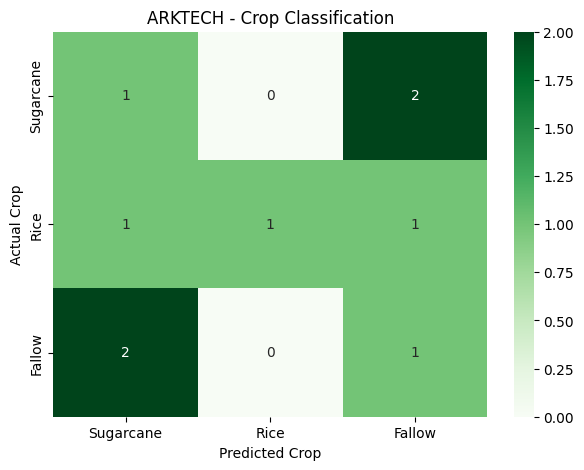

              precision    recall  f1-score   support

   Sugarcane       0.25      0.33      0.29         3
        Rice       1.00      0.33      0.50         3
      Fallow       0.25      0.33      0.29         3

    accuracy                           0.33         9
   macro avg       0.50      0.33      0.36         9
weighted avg       0.50      0.33      0.36         9



In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Predictions
predictions = model.predict(X_test)

y_pred = predictions.argmax(axis=1)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Sugarcane', 'Rice', 'Fallow'],
    yticklabels=['Sugarcane', 'Rice', 'Fallow']
)

plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.title("ARKTECH - Crop Classification")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=['Sugarcane', 'Rice', 'Fallow'],
    zero_division=0
))

In [ ]:
# Train ARKTECH model again

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=4,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed successfully!")

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.3750 - loss: 1.1239 - val_accuracy: 0.2000 - val_loss: 1.0405
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5000 - loss: 1.0482 - val_accuracy: 0.4000 - val_loss: 1.0688
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5000 - loss: 1.0718 - val_accuracy: 0.4000 - val_loss: 1.0913
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5000 - loss: 1.0007 - val_accuracy: 0.4000 - val_loss: 1.1134
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5000 - loss: 0.9488 - val_accuracy: 0.0000e+00 - val_loss: 1.1428
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5000 - loss: 0.9713 - val_accuracy: 0.0000e+00 - val_loss: 1.1885
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4375 - loss: 0.9571 - val_accuracy: 0.0000e+00 - val_loss: 1.2422
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5000 - loss: 0.8994 - val_accuracy: 0.0000

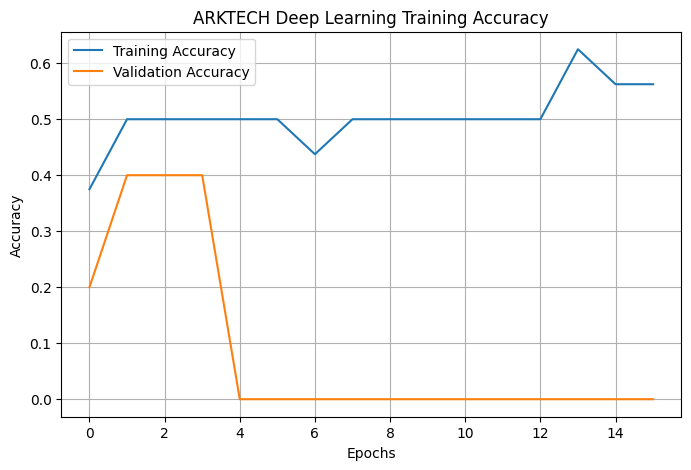

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('ARKTECH Deep Learning Training Accuracy')

plt.legend()
plt.grid()
plt.show()

In [ ]:
model.save('/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Crop_Model.keras')

print("ARKTECH Model Saved Successfully!")

ARKTECH Model Saved Successfully!


In [ ]:
import joblib

joblib.dump(
    scaler,
    '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Scaler.pkl'
)

print("Scaler saved successfully!")

Scaler saved successfully!


In [ ]:
import os

path = '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/'

for file in os.listdir(path):
    print("✅", file)

✅ Crop_Training_Data (1).csv
✅ Crop_Training_Data.csv
✅ Satellite_Data_Mandya.tif
✅ ARKTECH_Crop_Model.keras
✅ ARKTECH_Scaler.pkl


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install rasterio numpy matplotlib scikit-learn tensorflow -q

import rasterio
import numpy as np
import matplotlib.pyplot as plt
import os

In [ ]:
import rasterio
import numpy as np

satellite_path = "/content/drive/MyDrive/Satellite_Data_Mandya.tif"

stress_path = "/content/drive/MyDrive/Stress_Mask_Mandya.tif"

# Load satellite image
with rasterio.open(satellite_path) as src:
    satellite = src.read()
    satellite_profile = src.profile

# Load stress mask
with rasterio.open(stress_path) as src:
    stress_mask = src.read(1)

print("Satellite Image Shape:", satellite.shape)
print("Stress Mask Shape:", stress_mask.shape)

print("Satellite Bands:", satellite.shape[0])
print("Stress Classes:", np.unique(stress_mask))

RasterioIOError: /content/drive/MyDrive/Satellite_Data_Mandya.tif: No such file or directory

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

search_folder = "/content/drive/MyDrive"

print("Searching Google Drive for ARKTECH files...\n")

for root, dirs, files in os.walk(search_folder):
    for file in files:
        if file.endswith((".tif", ".tiff")):
            print(os.path.join(root, file))

Searching Google Drive for ARKTECH files...

/content/drive/MyDrive/ARKTECH_ISRO/Combined_Stress_Mandya.tif
/content/drive/MyDrive/ARKTECH_ISRO/VCI_Stress_Mandya.tif
/content/drive/MyDrive/ARKTECH_ISRO/Irrigation_Advisory_Mandya.tif
/content/drive/MyDrive/ARKTECH_ISRO/Crop_Classification_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif


In [ ]:
import glob

satellite_files = glob.glob(
    "/content/drive/MyDrive/**/Satellite_Data_Mandya.tif",
    recursive=True
)

stress_files = glob.glob(
    "/content/drive/MyDrive/**/Stress_Mask_Mandya.tif",
    recursive=True
)

print("Satellite:", satellite_files)
print("Stress Mask:", stress_files)

Satellite: ['/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif']
Stress Mask: ['/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif']


In [ ]:
import rasterio
import numpy as np

satellite_path = satellite_files[0]
stress_path = stress_files[0]

with rasterio.open(satellite_path) as src:
    satellite = src.read()
    satellite_profile = src.profile

with rasterio.open(stress_path) as src:
    stress_mask = src.read(1)

print("\nARKTECH DATA LOADED SUCCESSFULLY!")

print("Satellite Shape:", satellite.shape)
print("Stress Mask Shape:", stress_mask.shape)
print("Satellite Bands:", satellite.shape[0])
print("Stress Classes:", np.unique(stress_mask))


ARKTECH DATA LOADED SUCCESSFULLY!
Satellite Shape: (13, 4455, 4454)
Stress Mask Shape: (4455, 4454)
Satellite Bands: 13
Stress Classes: [0 1]


In [ ]:
import numpy as np

unique, counts = np.unique(stress_mask, return_counts=True)

print("Moisture Stress Distribution:")

for cls, count in zip(unique, counts):
    print(f"Class {cls}: {count:,} pixels ({count/ stress_mask.size*100:.2f}%)")

Moisture Stress Distribution:
Class 0: 10,861,296 pixels (54.74%)
Class 1: 8,981,274 pixels (45.26%)


In [ ]:
satellite = satellite.astype(np.float32)

X = np.zeros_like(
    np.moveaxis(satellite, 0, -1),
    dtype=np.float32
)

image = np.moveaxis(satellite, 0, -1)

for band in range(image.shape[-1]):

    band_data = image[:, :, band]

    valid = np.isfinite(band_data)

    p2, p98 = np.percentile(
        band_data[valid],
        [2, 98]
    )

    X[:, :, band] = np.clip(
        (band_data - p2) / (p98 - p2 + 1e-8),
        0, 1
    )

X = np.nan_to_num(X)

print("Normalization completed!")
print("Normalized Image:", X.shape)

Normalization completed!
Normalized Image: (4455, 4454, 13)


In [ ]:
PATCH_SIZE = 128

X_patches = []
Y_patches = []

for i in range(0, X.shape[0] - PATCH_SIZE + 1, PATCH_SIZE):

    for j in range(0, X.shape[1] - PATCH_SIZE + 1, PATCH_SIZE):

        img_patch = X[
            i:i+PATCH_SIZE,
            j:j+PATCH_SIZE,
            :
        ]

        mask_patch = stress_mask[
            i:i+PATCH_SIZE,
            j:j+PATCH_SIZE
        ]

        X_patches.append(img_patch)
        Y_patches.append(mask_patch)

X_patches = np.array(X_patches, dtype=np.float32)

Y_patches = np.array(Y_patches, dtype=np.uint8)

Y_patches = np.expand_dims(Y_patches, axis=-1)

print("Patch Generation Completed!")

print("X Shape:", X_patches.shape)
print("Y Shape:", Y_patches.shape)

Patch Generation Completed!
X Shape: (1156, 128, 128, 13)
Y Shape: (1156, 128, 128, 1)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_patches,
    Y_patches,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (924, 128, 128, 13)
Testing: (232, 128, 128, 13)


In [ ]:
import os

output_folder = "/content/drive/MyDrive/ARKTECH_UNET_DATA"

os.makedirs(output_folder, exist_ok=True)

np.save(output_folder + "/X_train.npy", X_train)
np.save(output_folder + "/X_test.npy", X_test)

np.save(output_folder + "/Y_train.npy", Y_train)
np.save(output_folder + "/Y_test.npy", Y_test)

print("ARKTECH U-Net Dataset Saved Successfully!")

ARKTECH U-Net Dataset Saved Successfully!


In [ ]:
import numpy as np

path = "/content/drive/MyDrive/ARKTECH_UNET_DATA/"

X_train = np.load(path + "X_train.npy")
X_test = np.load(path + "X_test.npy")

Y_train = np.load(path + "Y_train.npy")
Y_test = np.load(path + "Y_test.npy")

print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)

print("Training Masks:", Y_train.shape)
print("Testing Masks:", Y_test.shape)

print("Dataset Loaded Successfully!")

Training Images: (924, 128, 128, 13)
Testing Images: (232, 128, 128, 13)
Training Masks: (924, 128, 128, 1)
Testing Masks: (232, 128, 128, 1)
Dataset Loaded Successfully!


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# U-Net Architecture

def build_unet(input_shape=(128, 128, 13)):

    inputs = layers.Input(input_shape)

    # ENCODER 1
    c1 = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(32, 3, activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D()(c1)

    # ENCODER 2
    c2 = layers.Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(64, 3, activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D()(c2)

    # ENCODER 3
    c3 = layers.Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(128, 3, activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D()(c3)

    # BOTTLENECK
    c4 = layers.Conv2D(256, 3, activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(256, 3, activation='relu', padding='same')(c4)

    # DECODER 1
    u5 = layers.UpSampling2D()(c4)
    u5 = layers.Concatenate()([u5, c3])

    c5 = layers.Conv2D(128, 3, activation='relu', padding='same')(u5)
    c5 = layers.Conv2D(128, 3, activation='relu', padding='same')(c5)

    # DECODER 2
    u6 = layers.UpSampling2D()(c5)
    u6 = layers.Concatenate()([u6, c2])

    c6 = layers.Conv2D(64, 3, activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(64, 3, activation='relu', padding='same')(c6)

    # DECODER 3
    u7 = layers.UpSampling2D()(c6)
    u7 = layers.Concatenate()([u7, c1])

    c7 = layers.Conv2D(32, 3, activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(32, 3, activation='relu', padding='same')(c7)

    # OUTPUT
    outputs = layers.Conv2D(
        1, 1, activation='sigmoid'
    )(c7)

    return models.Model(inputs, outputs)


model = build_unet()

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 13)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      3,776 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_3[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_5[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_6[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_3[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_7[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 16, 16,    │          0 │ conv2d_8[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_4[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_9[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_10[0][0]   │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 32, 32,    │    442,496 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_11[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_12[0][0] 

 Total params: 1,949,761 (7.44 MB)

 Trainable params: 1,949,761 (7.44 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

print("ARKTECH U-Net Model Compiled Successfully!")

ARKTECH U-Net Model Compiled Successfully!


In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/ARKTECH_UNET_MODEL.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    Y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=8,
    callbacks=callbacks
)

Epoch 1/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 429s 5s/step - accuracy: 0.7652 - loss: 0.5091 - precision: 0.7870 - recall: 0.6594 - val_accuracy: 0.8231 - val_loss: 0.3946 - val_precision: 0.7667 - val_recall: 0.8694
Epoch 2/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 422s 5s/step - accuracy: 0.8446 - loss: 0.3481 - precision: 0.8411 - recall: 0.8093 - val_accuracy: 0.8638 - val_loss: 0.3081 - val_precision: 0.8361 - val_recall: 0.8656
Epoch 3/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 416s 4s/step - accuracy: 0.8679 - loss: 0.2985 - precision: 0.8643 - recall: 0.8399 - val_accuracy: 0.8781 - val_loss: 0.2775 - val_precision: 0.8664 - val_recall: 0.8605
Epoch 4/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 434s 5s/step - accuracy: 0.8789 - loss: 0.2753 - precision: 0.8753 - recall: 0.8539 - val_accuracy: 0.8856 - val_loss: 0.2616 - val_precision: 0.8775 - val_recall: 0.8652
Epoch 5/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 426s 4s/step - accuracy: 0.8859 - loss: 0.2608 - precision: 0.8825 - recall: 0.8625 - val_accuracy: 0.8893 - val_loss: 0.2534 

In [ ]:
import tensorflow as tf

results = model.evaluate(
    X_test,
    Y_test,
    batch_size=4,
    verbose=1
)

for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

58/58 ━━━━━━━━━━━━━━━━━━━━ 34s 557ms/step - accuracy: 0.9212 - loss: 0.1873 - precision: 0.9142 - recall: 0.9101
loss: 0.1873
compile_metrics: 0.9212


In [ ]:
import numpy as np

predictions = model.predict(X_test, batch_size=4)

predicted_masks = (predictions > 0.5).astype(np.uint8)

true_masks = Y_test.astype(np.uint8)

intersection = np.sum(predicted_masks * true_masks)

union = np.sum(predicted_masks) + np.sum(true_masks) - intersection

iou = intersection / (union + 1e-7)

dice = (2 * intersection) / (
    np.sum(predicted_masks) + np.sum(true_masks) + 1e-7
)

print("ARKTECH MODEL EVALUATION")
print("------------------------")
print(f"IoU Score:  {iou:.4f}")
print(f"Dice Score: {dice:.4f}")

58/58 ━━━━━━━━━━━━━━━━━━━━ 32s 553ms/step
ARKTECH MODEL EVALUATION
------------------------
IoU Score:  0.8385
Dice Score: 0.9122


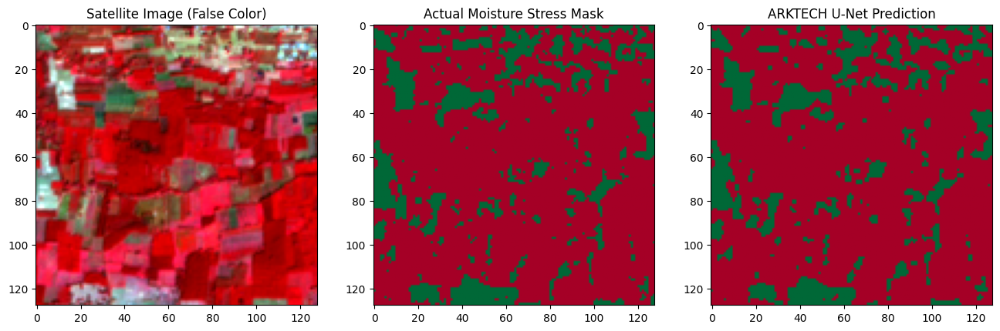

In [ ]:
import matplotlib.pyplot as plt

index = 0

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(X_test[index][:, :, [3, 2, 1]])
plt.title("Satellite Image (False Color)")

plt.subplot(1, 3, 2)
plt.imshow(Y_test[index].squeeze(), cmap="RdYlGn")
plt.title("Actual Moisture Stress Mask")

plt.subplot(1, 3, 3)
plt.imshow(predicted_masks[index].squeeze(), cmap="RdYlGn")
plt.title("ARKTECH U-Net Prediction")

plt.show()

In [ ]:
model.save(
    "/content/drive/MyDrive/ARKTECH_UNET_FINAL.keras"
)

print("ARKTECH U-Net Model Saved Successfully!")

ARKTECH U-Net Model Saved Successfully!


In [ ]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import tensorflow as tf

PATCH_SIZE = 128
BATCH_SIZE = 4

# Original satellite image: (13, 4455, 4454)
image = np.moveaxis(satellite, 0, -1).astype(np.float32)

# Apply the same normalization method used during training
for band in range(image.shape[-1]):
    band_data = image[:, :, band]

    valid = np.isfinite(band_data)

    p2, p98 = np.percentile(
        band_data[valid], [2, 98]
    )

    image[:, :, band] = np.clip(
        (band_data - p2) / (p98 - p2 + 1e-8),
        0, 1
    )

image = np.nan_to_num(image)

height, width, channels = image.shape

stress_prediction = np.zeros(
    (height, width), dtype=np.uint8
)

patches = []
coordinates = []

for i in range(0, height, PATCH_SIZE):
    for j in range(0, width, PATCH_SIZE):

        patch = image[
            i:min(i+PATCH_SIZE, height),
            j:min(j+PATCH_SIZE, width),
            :
        ]

        ph, pw, _ = patch.shape

        padded = np.zeros(
            (PATCH_SIZE, PATCH_SIZE, channels),
            dtype=np.float32
        )

        padded[:ph, :pw, :] = patch

        patches.append(padded)
        coordinates.append((i, j, ph, pw))

        if len(patches) == BATCH_SIZE:

            predictions = model.predict(
                np.array(patches),
                verbose=0
            )

            for k, (y, x, h, w) in enumerate(coordinates):
                stress_prediction[
                    y:y+h, x:x+w
                ] = (
                    predictions[k, :h, :w, 0] > 0.5
                ).astype(np.uint8)

            patches = []
            coordinates = []

# Process remaining patches
if patches:
    predictions = model.predict(
        np.array(patches),
        verbose=0
    )

    for k, (y, x, h, w) in enumerate(coordinates):
        stress_prediction[
            y:y+h, x:x+w
        ] = (
            predictions[k, :h, :w, 0] > 0.5
        ).astype(np.uint8)

print("Full Mandya Stress Prediction Completed!")
print("Output Shape:", stress_prediction.shape)

Full Mandya Stress Prediction Completed!
Output Shape: (4455, 4454)


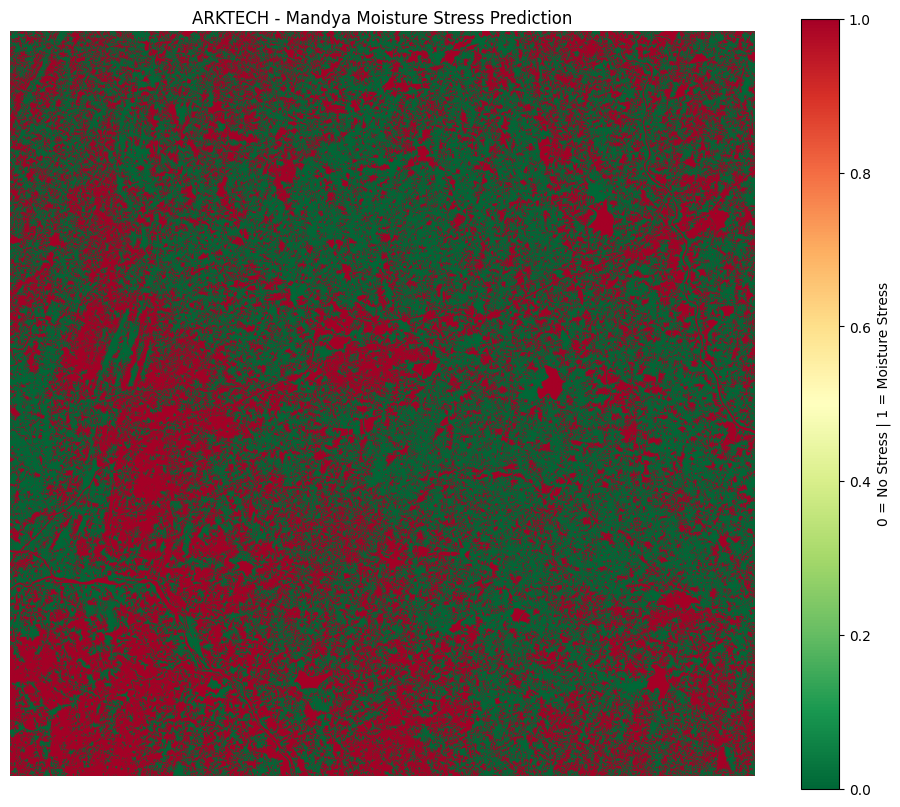

In [ ]:
plt.figure(figsize=(12, 10))

plt.imshow(
    stress_prediction,
    cmap="RdYlGn_r",
    vmin=0,
    vmax=1
)

plt.title("ARKTECH - Mandya Moisture Stress Prediction")

plt.colorbar(
    label="0 = No Stress | 1 = Moisture Stress"
)

plt.axis("off")
plt.show()

In [ ]:
output_path = "/content/drive/MyDrive/ARKTECH_Mandya_Stress_Prediction.tif"

profile = satellite_profile.copy()

profile.update(
    count=1,
    dtype=rasterio.uint8,
    compress="lzw"
)

with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(stress_prediction, 1)

print("GeoTIFF Exported Successfully!")
print(output_path)

GeoTIFF Exported Successfully!
/content/drive/MyDrive/ARKTECH_Mandya_Stress_Prediction.tif


In [ ]:
import rasterio
import numpy as np

path = "/content/drive/MyDrive/ARKTECH_Mandya_Stress_Prediction.tif"

with rasterio.open(path) as src:

    prediction = src.read(1)

    print("ARKTECH GEO-TIFF VALIDATION")
    print("---------------------------")

    print("Dimensions:", src.width, src.height)
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Pixel Size:", src.res)
    print("Data Type:", src.dtypes)

    unique, counts = np.unique(
        prediction, return_counts=True
    )

    for cls, count in zip(unique, counts):
        print(f"Class {cls}: {count:,} pixels")

    print("GeoTIFF Validation Completed!")

ARKTECH GEO-TIFF VALIDATION
---------------------------
Dimensions: 4454 4455
CRS: EPSG:4326
Bounds: BoundingBox(left=76.69995558869299, bottom=12.299912533221313, right=77.10006521623983, top=12.70011199229656)
Pixel Size: (8.983152841195215e-05, 8.983152841195215e-05)
Data Type: ('uint8',)
Class 0: 10,917,342 pixels
Class 1: 8,925,228 pixels
GeoTIFF Validation Completed!


In [ ]:
total_pixels = prediction.size

stressed_pixels = np.sum(prediction == 1)
healthy_pixels = np.sum(prediction == 0)

stress_percentage = (
    stressed_pixels / total_pixels
) * 100

healthy_percentage = (
    healthy_pixels / total_pixels
) * 100

print("MANDYA MOISTURE STRESS REPORT")
print("-----------------------------")

print(f"Stressed Area: {stress_percentage:.2f}%")
print(f"Healthy Area: {healthy_percentage:.2f}%")

MANDYA MOISTURE STRESS REPORT
-----------------------------
Stressed Area: 44.98%
Healthy Area: 55.02%


In [ ]:
import rasterio

path = "/content/drive/MyDrive/ARKTECH_Mandya_Stress_Prediction.tif"

with rasterio.open(path) as src:

    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Transform:", src.transform)

CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Bounds: BoundingBox(left=76.69995558869299, bottom=12.299912533221313, right=77.10006521623983, top=12.70011199229656)
Transform: | 0.00, 0.00, 76.70|
| 0.00,-0.00, 12.70|
| 0.00, 0.00, 1.00|


In [ ]:
import rasterio
import numpy as np
from pyproj import Geod

path = "/content/drive/MyDrive/ARKTECH_Mandya_Stress_Prediction.tif"

geod = Geod(ellps="WGS84")

with rasterio.open(path) as src:

    prediction = src.read(1)
    transform = src.transform

    height, width = prediction.shape

    stressed_area = 0
    healthy_area = 0

    for row in range(height):

        top = transform.f + row * transform.e
        bottom = top + transform.e

        left = transform.c
        right = left + transform.a

        pixel_area, perimeter = geod.polygon_area_perimeter(
            [left, right, right, left],
            [top, top, bottom, bottom]
        )

        pixel_area = abs(pixel_area)

        stressed_count = np.count_nonzero(prediction[row] == 1)
        healthy_count = np.count_nonzero(prediction[row] == 0)

        stressed_area += stressed_count * pixel_area
        healthy_area += healthy_count * pixel_area

print("\nARKTECH AREA ANALYSIS")
print("-----------------------------")

print(f"Stressed Area: {stressed_area/10000:.2f} hectares")
print(f"Healthy Area: {healthy_area/10000:.2f} hectares")

print(f"Total Area: {(stressed_area+healthy_area)/10000:.2f} hectares")

print("\nArea Calculation Completed Successfully!")


ARKTECH AREA ANALYSIS
-----------------------------
Stressed Area: 86610.73 hectares
Healthy Area: 105935.00 hectares
Total Area: 192545.72 hectares

Area Calculation Completed Successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

search_folder = "/content/drive/MyDrive"

print("Searching for ARKTECH satellite files...\n")

tif_files = []

for root, dirs, files in os.walk(search_folder):
    for file in files:
        if file.lower().endswith((".tif", ".tiff")):
            full_path = os.path.join(root, file)
            tif_files.append(full_path)
            print(full_path)

print("\nTotal TIFF files found:", len(tif_files))

Searching for ARKTECH satellite files...

/content/drive/MyDrive/ARKTECH_Mandya_Stress_Prediction.tif
/content/drive/MyDrive/ARKTECH_ISRO/Combined_Stress_Mandya.tif
/content/drive/MyDrive/ARKTECH_ISRO/VCI_Stress_Mandya.tif
/content/drive/MyDrive/ARKTECH_ISRO/Irrigation_Advisory_Mandya.tif
/content/drive/MyDrive/ARKTECH_ISRO/Crop_Classification_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif

Total TIFF files found: 7


In [ ]:
satellite_candidates = [
    f for f in tif_files
    if "satellite_data_mandya" in os.path.basename(f).lower()
]

print("Satellite candidates:")

for i, file in enumerate(satellite_candidates):
    print(i, file)

Satellite candidates:
0 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif


In [ ]:
import rasterio
import numpy as np

satellite_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif"

with rasterio.open(satellite_path) as src:
    satellite = src.read()
    profile = src.profile.copy()

print("ARKTECH SATELLITE DATA LOADED SUCCESSFULLY!")
print("Image shape:", satellite.shape)
print("Number of bands:", satellite.shape[0])
print("CRS:", profile["crs"])
print("Image dimensions:", satellite.shape[1:])
print("Data type:", satellite.dtype)

ARKTECH SATELLITE DATA LOADED SUCCESSFULLY!
Image shape: (13, 4455, 4454)
Number of bands: 13
CRS: EPSG:4326
Image dimensions: (4455, 4454)
Data type: float32


In [ ]:
import rasterio
import numpy as np

with rasterio.open(satellite_path) as src:
    satellite = src.read()
    profile = src.profile.copy()

print("\nARKTECH SATELLITE DATA LOADED!")

print("Shape:", satellite.shape)
print("Bands:", satellite.shape[0])
print("CRS:", profile["crs"])
print("Dimensions:", satellite.shape[1:])


ARKTECH SATELLITE DATA LOADED!
Shape: (13, 4455, 4454)
Bands: 13
CRS: EPSG:4326
Dimensions: (4455, 4454)


CRS: EPSG:4326
Dimensions: (4455, 4454)
Bands: 13
NoData: None


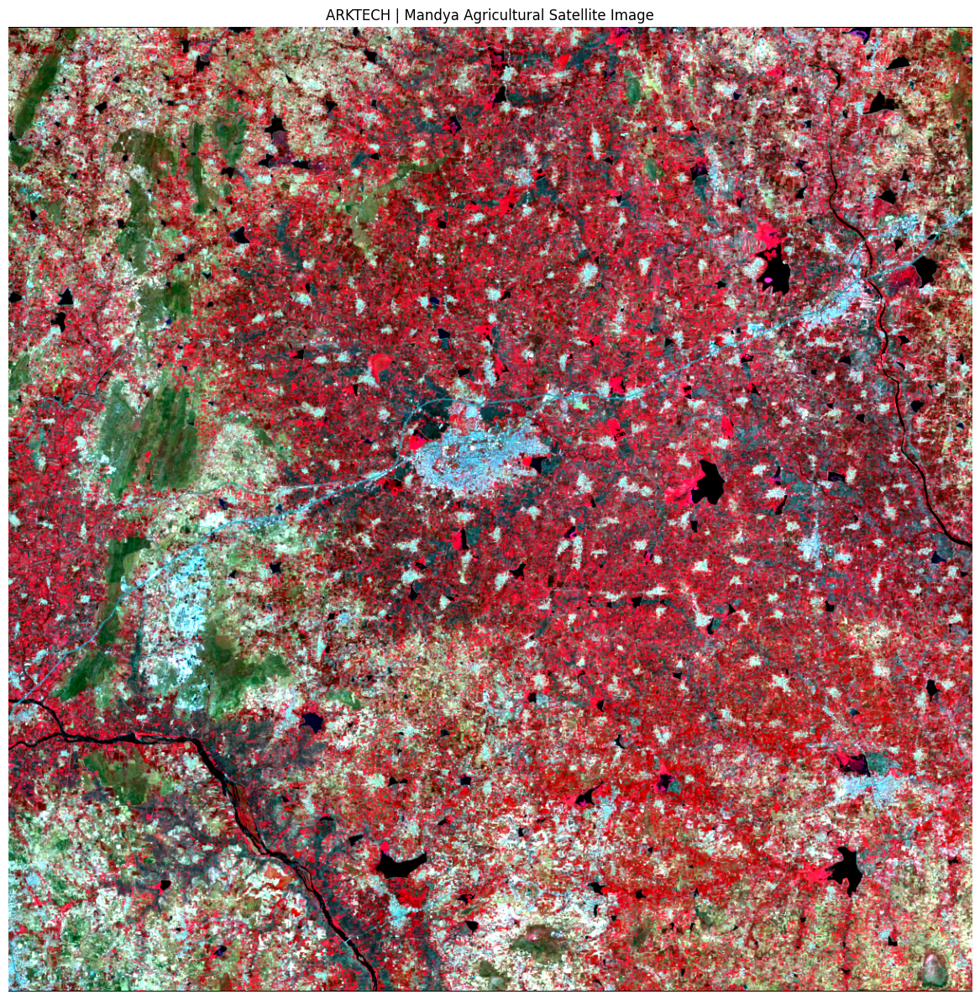

RGB visualization generated successfully!


In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.enums import Resampling

satellite_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif"

with rasterio.open(satellite_path) as src:

    print("CRS:", src.crs)
    print("Dimensions:", src.shape)
    print("Bands:", src.count)
    print("NoData:", src.nodata)

    # Read a smaller image for faster visualization
    image = src.read(
        [4, 3, 2],
        out_shape=(3, 1200, 1200),
        resampling=Resampling.bilinear,
        masked=True
    )

    rgb_bands = []

    for band in image:

        band = np.ma.filled(
            band.astype(np.float32), np.nan
        )

        valid = band[np.isfinite(band)]

        if len(valid) == 0:
            raise ValueError("Band contains no valid pixels")

        p2, p98 = np.percentile(valid, [2, 98])

        normalized = np.clip(
            (band - p2) / (p98 - p2 + 1e-8),
            0, 1
        )

        normalized = np.nan_to_num(normalized)

        rgb_bands.append(normalized)

    rgb = np.dstack(rgb_bands)

plt.figure(figsize=(12, 12))
plt.imshow(rgb)
plt.title("ARKTECH | Mandya Agricultural Satellite Image")
plt.axis("off")
plt.tight_layout()
plt.show()

print("RGB visualization generated successfully!")

In [ ]:
import os
import rasterio
import numpy as np

from rasterio.windows import Window
from rasterio.windows import transform as window_transform

# Paths
input_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif"

output_dir = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles"

os.makedirs(output_dir, exist_ok=True)

TILE_SIZE = 256

tile_count = 0

with rasterio.open(input_path) as src:

    width = src.width
    height = src.height

    print("Original dimensions:", width, height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Band descriptions:", src.descriptions)

    for y in range(0, height, TILE_SIZE):

        for x in range(0, width, TILE_SIZE):

            window = Window(
                x,
                y,
                min(TILE_SIZE, width-x),
                min(TILE_SIZE, height-y)
            )

            # Read all 13 bands
            data = src.read(
                window=window,
                boundless=True,
                out_shape=(src.count, TILE_SIZE, TILE_SIZE),
                fill_value=0
            )

            # Preserve geospatial information
            transform = window_transform(window, src.transform)

            profile = src.profile.copy()

            profile.update({
                "driver": "GTiff",
                "height": TILE_SIZE,
                "width": TILE_SIZE,
                "transform": transform,
                "compress": "lzw"
            })

            tile_name = f"tile_{y}_{x}.tif"

            tile_path = os.path.join(
                output_dir,
                tile_name
            )

            with rasterio.open(tile_path, "w", **profile) as dst:
                dst.write(data)

            tile_count += 1

print("\nTILING COMPLETED!")
print("Total tiles:", tile_count)
print("Saved location:", output_dir)

Original dimensions: 4454 4455
Bands: 13
CRS: EPSG:4326
Band descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI', 'VV', 'VH', 'SMI', 'Contrast', 'Entropy')

TILING COMPLETED!
Total tiles: 324
Saved location: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles


In [ ]:
import os
import rasterio
from rasterio.windows import Window, transform as window_transform

input_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif"

output_dir = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles"

os.makedirs(output_dir, exist_ok=True)

tile_size = 256
count = 0

with rasterio.open(input_path) as src:

    for y in range(0, src.height, tile_size):

        for x in range(0, src.width, tile_size):

            window = Window(x, y, tile_size, tile_size)

            data = src.read(
                window=window,
                boundless=True,
                fill_value=0
            )

            profile = src.profile.copy()

            profile.update(
                height=tile_size,
                width=tile_size,
                transform=window_transform(window, src.transform),
                compress="lzw"
            )

            filename = f"tile_{y}_{x}.tif"

            with rasterio.open(
                os.path.join(output_dir, filename),
                "w",
                **profile
            ) as dst:

                dst.write(data)

            count += 1

print("RE-GENERATION COMPLETED")
print("Total tiles:", count)
print("Tile dimensions: 256 x 256")
print("Bands: 13")

RE-GENERATION COMPLETED
Total tiles: 324
Tile dimensions: 256 x 256
Bands: 13


Total tiles: 324

Sample: tile_2048_3072.tif
Dimensions: 256 256
Bands: 13
CRS: EPSG:4326
Transform: | 0.00, 0.00, 76.98|
| 0.00,-0.00, 12.52|
| 0.00, 0.00, 1.00|


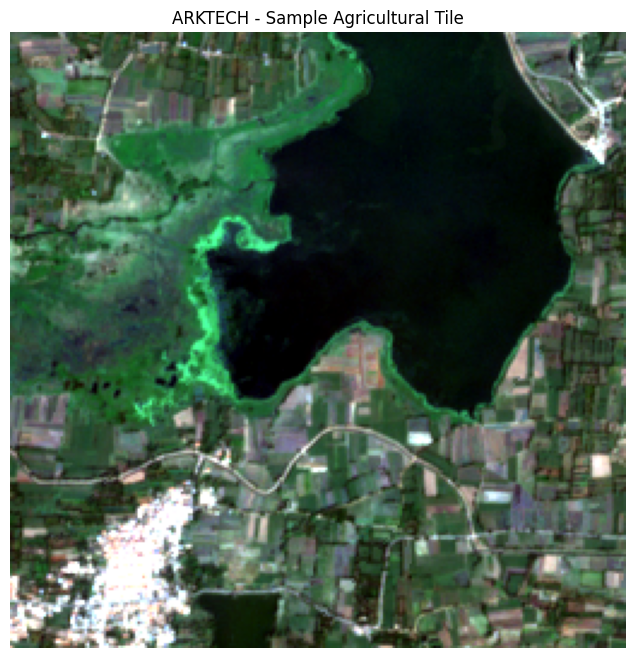


TILE VALIDATION COMPLETED!


In [ ]:
import os
import glob
import rasterio
import matplotlib.pyplot as plt
import numpy as np

tile_dir = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles"

tiles = sorted(glob.glob(tile_dir + "/tile_*.tif"))

print("Total tiles:", len(tiles))

# Inspect one tile
sample_tile = tiles[100]

with rasterio.open(sample_tile) as src:

    print("\nSample:", os.path.basename(sample_tile))
    print("Dimensions:", src.width, src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Transform:", src.transform)

    # True colour: B4, B3, B2
    rgb = src.read([3, 2, 1]).astype(np.float32)

def normalize(band):
    p2, p98 = np.percentile(band, [2, 98])
    return np.clip((band-p2)/(p98-p2+1e-8), 0, 1)

rgb_image = np.dstack([
    normalize(rgb[0]),
    normalize(rgb[1]),
    normalize(rgb[2])
])

plt.figure(figsize=(8, 8))
plt.imshow(rgb_image)
plt.title("ARKTECH - Sample Agricultural Tile")
plt.axis("off")
plt.show()

print("\nTILE VALIDATION COMPLETED!")

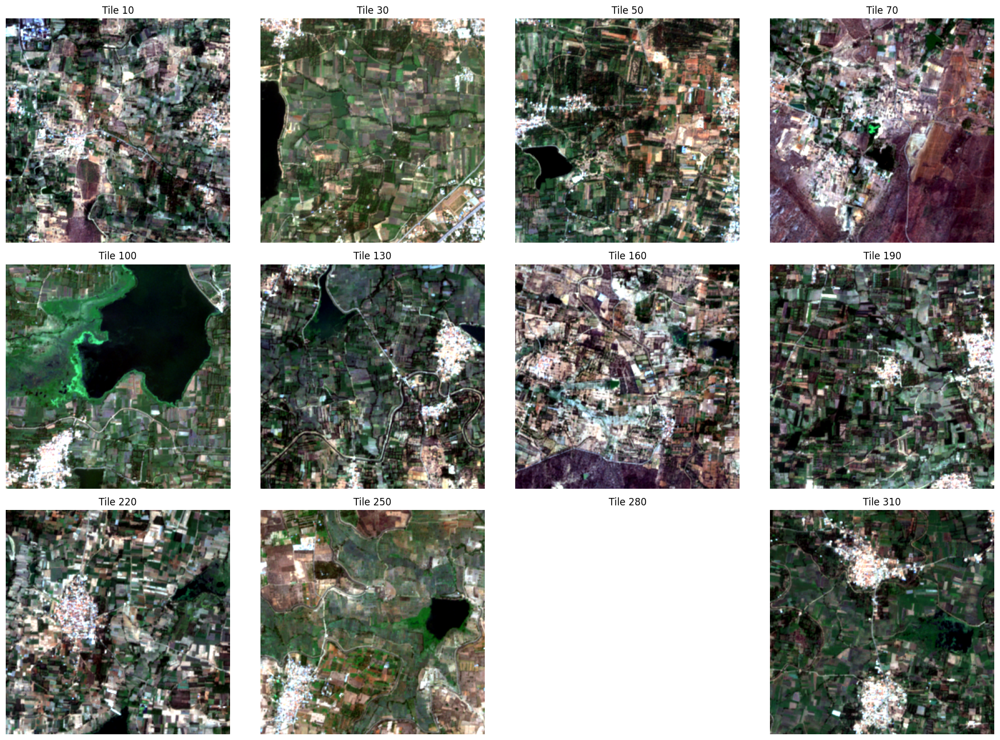

In [ ]:
import os
import glob
import rasterio
import numpy as np
import matplotlib.pyplot as plt

tile_dir = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles"

tiles = sorted(glob.glob(tile_dir + "/tile_*.tif"))

selected = [10, 30, 50, 70, 100, 130,
            160, 190, 220, 250, 280, 310]

fig, axes = plt.subplots(3, 4, figsize=(18, 13))

for ax, idx in zip(axes.flat, selected):

    with rasterio.open(tiles[idx]) as src:
        rgb = src.read([3, 2, 1]).astype(np.float32)

    bands = []

    for band in rgb:
        p2, p98 = np.percentile(band, [2, 98])
        band = np.clip((band-p2)/(p98-p2+1e-8), 0, 1)
        bands.append(band)

    image = np.dstack(bands)

    ax.imshow(image)
    ax.set_title(f"Tile {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

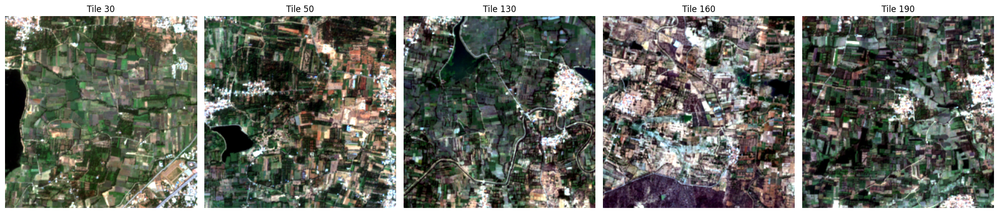

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

tile_dir = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles"

tiles = sorted(glob.glob(tile_dir + "/tile_*.tif"))

selected = [30, 50, 130, 160, 190]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, idx in zip(axes, selected):

    with rasterio.open(tiles[idx]) as src:
        rgb = src.read([3, 2, 1]).astype(np.float32)

    channels = []

    for band in rgb:
        p2, p98 = np.percentile(band, [2, 98])
        channels.append(
            np.clip((band-p2)/(p98-p2+1e-8), 0, 1)
        )

    ax.imshow(np.dstack(channels))
    ax.set_title(f"Tile {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

folders = [
    "Field_Annotations",
    "Field_Annotations/GeoJSON",
    "Field_Annotations/Masks",
    "Field_Annotations/Preview",
    "Field_Segmentation_Dataset/Images",
    "Field_Segmentation_Dataset/Labels"
]

for folder in folders:
    os.makedirs(os.path.join(BASE, folder), exist_ok=True)

print("ARKTECH ANNOTATION WORKSPACE CREATED!")

for folder in folders:
    print("Created:", folder)

ARKTECH ANNOTATION WORKSPACE CREATED!
Created: Field_Annotations
Created: Field_Annotations/GeoJSON
Created: Field_Annotations/Masks
Created: Field_Annotations/Preview
Created: Field_Segmentation_Dataset/Images
Created: Field_Segmentation_Dataset/Labels


In [ ]:
!pip install -q ipympl ipywidgets rasterio shapely geopandas

In [ ]:
!pip install -q ipympl ipywidgets

print("Interactive libraries installed successfully!")

Interactive libraries installed successfully!


In [ ]:
import matplotlib
import matplotlib.pyplot as plt

# Reset to standard Matplotlib backend
matplotlib.use("Agg", force=True)

print("Matplotlib version:", matplotlib.__version__)
print("Backend:", matplotlib.get_backend())
print("ARKTECH plotting environment ready!")

Matplotlib version: 3.10.0
Backend: Agg
ARKTECH plotting environment ready!


In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

tile_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_7680.tif"

with rasterio.open(tile_path) as src:
    rgb = src.read([3, 2, 1]).astype(np.float32)

def normalize(band):
    p2, p98 = np.percentile(band, [2, 98])
    return np.clip((band-p2)/(p98-p2+1e-8), 0, 1)

image = np.dstack([
    normalize(rgb[0]),
    normalize(rgb[1]),
    normalize(rgb[2])
])

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title("ARKTECH Satellite Tile")
plt.axis("off")
plt.show()

RasterioIOError: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_7680.tif: No such file or directory

In [ ]:
import os
import glob

tile_dir = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles"

tiles = sorted(glob.glob(os.path.join(tile_dir, "tile_*.tif")))

print("Total tiles found:", len(tiles))

print("\nFirst 10 available tiles:")

for tile in tiles[:10]:
    print(os.path.basename(tile))

print("\nTile 30:", os.path.basename(tiles[30]))

Total tiles found: 324

First 10 available tiles:
tile_0_0.tif
tile_0_1024.tif
tile_0_1280.tif
tile_0_1536.tif
tile_0_1792.tif
tile_0_2048.tif
tile_0_2304.tif
tile_0_256.tif
tile_0_2560.tif
tile_0_2816.tif

Tile 30: tile_1024_3584.tif


In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Automatically select Tile 30
tile_path = tiles[30]

print("Loading:", os.path.basename(tile_path))

with rasterio.open(tile_path) as src:

    rgb = src.read([3, 2, 1]).astype(np.float32)

    transform = src.transform
    crs = src.crs

def normalize(band):
    p2, p98 = np.percentile(band, [2, 98])
    return np.clip(
        (band-p2)/(p98-p2+1e-8), 0, 1
    )

image = np.dstack([
    normalize(rgb[0]),
    normalize(rgb[1]),
    normalize(rgb[2])
])

plt.figure(figsize=(9, 9))
plt.imshow(image)
plt.title("ARKTECH - Tile 30 Annotation")
plt.axis("off")
plt.show()

print("Satellite tile loaded successfully!")

Loading: tile_1024_3584.tif
Satellite tile loaded successfully!


In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

tile_path = tiles[30]

with rasterio.open(tile_path) as src:

    rgb = src.read([3, 2, 1]).astype(np.float32)

    transform = src.transform
    crs = src.crs

    print("Tile:", tile_path)
    print("Dimensions:", src.width, src.height)
    print("Bands:", src.count)
    print("CRS:", crs)

def normalize(band):
    p2, p98 = np.percentile(band, [2, 98])
    return np.clip((band-p2)/(p98-p2+1e-8), 0, 1)

image = np.dstack([
    normalize(rgb[0]),
    normalize(rgb[1]),
    normalize(rgb[2])
])

plt.figure(figsize=(9, 9))
plt.imshow(image)
plt.title("ARKTECH - Tile 30")
plt.axis("off")
plt.show()

print("TILE LOADED SUCCESSFULLY!")

Tile: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_1024_3584.tif
Dimensions: 256 256
Bands: 13
CRS: EPSG:4326
TILE LOADED SUCCESSFULLY!


In [ ]:
!pip install -q opencv-python-headless shapely rasterio

Annotation image ready!


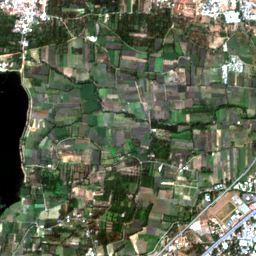

In [ ]:
import cv2
import numpy as np
import rasterio
import os
from google.colab.patches import cv2_imshow

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

tile_path = os.path.join(
    BASE, "Field_Tiles", "tile_1024_3584.tif"
)

with rasterio.open(tile_path) as src:
    rgb = src.read([3, 2, 1]).astype(np.float32)
    transform = src.transform
    crs = src.crs

def normalize(band):
    p2, p98 = np.percentile(band, [2, 98])
    return np.clip((band-p2)/(p98-p2+1e-8), 0, 1)

image = np.dstack([
    normalize(rgb[0]),
    normalize(rgb[1]),
    normalize(rgb[2])
])

image = (image * 255).astype(np.uint8)

# Convert RGB to BGR for OpenCV
display_image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

print("Annotation image ready!")
cv2_imshow(display_image)


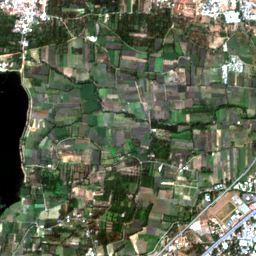

ANNOTATIONS SAVED!
Total fields: 1


In [ ]:
import json
import base64
import io

import numpy as np
from PIL import Image
from IPython.display import display, HTML
from google.colab import output

# Prepare satellite image
pil_image = Image.fromarray(image)

buffer = io.BytesIO()
pil_image.save(buffer, format="PNG")

image_base64 = base64.b64encode(
    buffer.getvalue()
).decode()

# Annotation storage
field_annotations = []

def receive_annotations(data):
    global field_annotations
    field_annotations = json.loads(data)

    print("ANNOTATIONS SAVED!")
    print("Total fields:", len(field_annotations))

    return "Success"

output.register_callback(
    "arktech.save_annotations",
    receive_annotations
)

html = """
<div style="font-family:Arial">

<h2>ARKTECH Field Boundary Annotation</h2>

<p>Tile 30 | Draw individual agricultural fields</p>

<canvas id="arkcanvas"
 width="768" height="768"
 style="width:100%;max-width:768px;
 border:2px solid #333;cursor:crosshair">
</canvas>

<br><br>

<button onclick="finishPolygon()">Finish Field</button>
<button onclick="undoPoint()">Undo Point</button>
<button onclick="undoPolygon()">Undo Field</button>
<button onclick="saveAnnotations()">Save Annotations</button>

<p id="status">Click on the image to mark field boundaries.</p>

<script>

const canvas = document.getElementById("arkcanvas");
const ctx = canvas.getContext("2d");

const img = new Image();

img.src = "data:image/png;base64,IMAGE_DATA";

let polygons = [];
let current = [];

img.onload = function() {
    draw();
};

function draw() {

    ctx.clearRect(0,0,768,768);
    ctx.drawImage(img,0,0,768,768);

    polygons.forEach((poly,index) => {

        ctx.beginPath();

        poly.forEach((p,i) => {
            if(i===0) ctx.moveTo(p.x,p.y);
            else ctx.lineTo(p.x,p.y);
        });

        ctx.closePath();

        ctx.fillStyle="rgba(0,255,0,0.20)";
        ctx.fill();

        ctx.strokeStyle="lime";
        ctx.lineWidth=3;
        ctx.stroke();

        ctx.fillStyle="yellow";
        ctx.font="18px Arial";

        ctx.fillText("F"+(index+1),
                     poly[0].x,poly[0].y);
    });

    if(current.length>0) {

        ctx.beginPath();

        current.forEach((p,i)=>{
            if(i===0) ctx.moveTo(p.x,p.y);
            else ctx.lineTo(p.x,p.y);
        });

        ctx.strokeStyle="red";
        ctx.lineWidth=3;
        ctx.stroke();

        current.forEach(p=>{
            ctx.beginPath();
            ctx.arc(p.x,p.y,5,0,Math.PI*2);
            ctx.fillStyle="yellow";
            ctx.fill();
        });
    }
}

canvas.addEventListener("click",function(e){

    const rect=canvas.getBoundingClientRect();

    const x=(e.clientX-rect.left)*768/rect.width;
    const y=(e.clientY-rect.top)*768/rect.height;

    current.push({x:x,y:y});

    draw();

});

function finishPolygon(){

    if(current.length<3){
        alert("At least 3 points required!");
        return;
    }

    polygons.push(current);
    current=[];

    document.getElementById("status").innerText =
        "Fields annotated: "+polygons.length;

    draw();
}

function undoPoint(){

    current.pop();
    draw();
}

function undoPolygon(){

    polygons.pop();
    draw();

    document.getElementById("status").innerText =
        "Fields annotated: "+polygons.length;
}

function saveAnnotations(){

    if(current.length>0){
        alert("Finish the current field first!");
        return;
    }

    const result=polygons.map((poly,index)=>({

        field_id:"ARK_FIELD_"+String(index+1).padStart(3,"0"),

        coordinates:poly.map(p=>({
            x:p.x/3,
            y:p.y/3
        }))

    }));

    google.colab.kernel.invokeFunction(
        "arktech.save_annotations",
        [JSON.stringify(result)],
        {}
    );

    document.getElementById("status").innerText =
        "Saved "+result.length+" field annotations!";
}

</script>
</div>
"""

html = html.replace("IMAGE_DATA", image_base64)

display(HTML(html))

In [ ]:
import os
import json
import cv2
import numpy as np
import rasterio

from shapely.geometry import Polygon, mapping
from shapely.geometry import MultiPolygon, GeometryCollection

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

tile_path = os.path.join(
    BASE, "Field_Tiles", "tile_1024_3584.tif"
)

geojson_path = os.path.join(
    BASE, "Field_Annotations/GeoJSON/tile_30.geojson"
)

mask_path = os.path.join(
    BASE, "Field_Annotations/Masks/tile_30_mask.png"
)

with rasterio.open(tile_path) as src:
    transform = src.transform
    crs = src.crs
    height = src.height
    width = src.width

features = []

mask = np.zeros((height, width), dtype=np.uint8)

for field in field_annotations:

    points = [
        (p["x"], p["y"])
        for p in field["coordinates"]
    ]

    polygon = Polygon(points)

    if not polygon.is_valid:
        polygon = polygon.buffer(0)

    if polygon.is_empty:
        continue

    # Handle Polygon and MultiPolygon
    if polygon.geom_type == "Polygon":
        geometries = [polygon]

    elif polygon.geom_type == "MultiPolygon":
        geometries = list(polygon.geoms)

    else:
        print("Skipping unsupported geometry:", polygon.geom_type)
        continue

    for geom in geometries:

        if geom.area < 1:
            continue

        # Pixel coordinates to geographic coordinates
        geographic_coords = [
            transform * (x, y)
            for x, y in geom.exterior.coords
        ]

        geo_polygon = Polygon(geographic_coords)

        features.append({
            "type": "Feature",
            "properties": {
                "field_id": field["field_id"],
                "tile": "tile_30",
                "class": "agricultural_field"
            },
            "geometry": mapping(geo_polygon)
        })

        # Field interior = 1
        polygon_pixels = np.array(
            geom.exterior.coords[:-1],
            dtype=np.int32
        )

        cv2.fillPoly(mask, [polygon_pixels], 1)

        # Field boundary = 2
        cv2.polylines(
            mask,
            [polygon_pixels],
            True,
            2,
            thickness=2
        )

# Save GeoJSON
geojson = {
    "type": "FeatureCollection",
    "name": "ARKTECH_Tile_30",
    "features": features
}

with open(geojson_path, "w") as f:
    json.dump(geojson, f, indent=2)

# Save mask
cv2.imwrite(mask_path, mask)

print("\nARKTECH EXPORT SUCCESSFUL!")
print("Total fields:", len(field_annotations))
print("GeoJSON features:", len(features))
print("Mask dimensions:", mask.shape)
print("Mask classes:", np.unique(mask))
print("CRS:", crs)
print("\nGeoJSON:", geojson_path)
print("Mask:", mask_path)


ARKTECH EXPORT SUCCESSFUL!
Total fields: 1
GeoJSON features: 9
Mask dimensions: (256, 256)
Mask classes: [0 1 2]
CRS: EPSG:4326

GeoJSON: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson
Mask: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/Masks/tile_30_mask.png


In [ ]:
import matplotlib.pyplot as plt
import rasterio
import cv2
import numpy as np

# Paths
tile_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_1024_3584.tif"

mask_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/Masks/tile_30_mask.png"

# Load satellite image
with rasterio.open(tile_path) as src:
    rgb = np.stack([
        src.read(3),  # B4 Red
        src.read(2),  # B3 Green
        src.read(1)   # B2 Blue
    ], axis=-1)

# Normalize for visualization
rgb = rgb.astype("float32")
rgb = np.clip(rgb / np.percentile(rgb, 98), 0, 1)

# Load mask
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Create overlay
overlay = rgb.copy()

# Highlight field interior
overlay[mask == 1] = (
    0.5 * overlay[mask == 1] +
    0.5 * np.array([0, 1, 0])
)

# Highlight boundaries
overlay[mask == 2] = [1, 0, 0]

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original Satellite Tile")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="viridis")
plt.title("Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Field Boundary Overlay")
plt.axis("off")

plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Exact mask path
MASK_PATH = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/Masks/tile_30_mask.png"

# Check file
if not os.path.exists(MASK_PATH):
    raise FileNotFoundError(f"Mask not found: {MASK_PATH}")

# Load mask
mask = cv2.imread(MASK_PATH, cv2.IMREAD_GRAYSCALE)

print("MASK LOADED SUCCESSFULLY!")
print("Mask dimensions:", mask.shape)
print("Mask classes:", np.unique(mask))

# Visualize
plt.figure(figsize=(8, 8))
plt.imshow(mask, cmap="viridis", interpolation="nearest")
plt.title("ARKTECH - Field Segmentation Mask")
plt.colorbar(label="Class ID")
plt.axis("off")
plt.show()

MASK LOADED SUCCESSFULLY!
Mask dimensions: (256, 256)
Mask classes: [0 1 2]


In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import cv2

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

# Load mask
mask_path = BASE + "/Field_Annotations/Masks/tile_30_mask.png"

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Load GeoJSON
geojson_path = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

fields = gpd.read_file(geojson_path)

# Locate satellite tile
satellite_path = BASE + "/Satellite_Data_Mandya.tif"

with rasterio.open(satellite_path) as src:

    print("Satellite dimensions:", src.width, src.height)
    print("Satellite bands:", src.count)
    print("Satellite CRS:", src.crs)

    # Read satellite data
    satellite = src.read([1, 2, 3])

    # Check GeoJSON CRS
    fields = fields.to_crs(src.crs)

    # Normalize image
    rgb = np.transpose(satellite, (1, 2, 0)).astype(float)

    for i in range(3):
        low, high = np.percentile(rgb[:, :, i], [2, 98])
        rgb[:, :, i] = np.clip(
            (rgb[:, :, i] - low) / (high - low + 1e-8),
            0, 1
        )

# Visualize mask
plt.figure(figsize=(7, 7))
plt.imshow(mask, cmap="viridis")
plt.title("ARKTECH Field Segmentation Mask")
plt.axis("off")
plt.show()

# Visualize satellite
plt.figure(figsize=(9, 7))
plt.imshow(rgb)
plt.title("Mandya Satellite Imagery")
plt.axis("off")
plt.show()

# Visualize GeoJSON
fig, ax = plt.subplots(figsize=(9, 9))

fields.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=2
)

ax.set_title("ARKTECH Annotated Field Boundaries")
plt.show()

Satellite dimensions: 4454 4455
Satellite bands: 13
Satellite CRS: EPSG:4326


In [ ]:
import rasterio
import os

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

satellite_path = BASE + "/Satellite_Data_Mandya.tif"

with rasterio.open(satellite_path) as src:

    print("===== SATELLITE INFORMATION =====")

    print("Dimensions:", src.width, src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("Bounds:", src.bounds)
    print("Resolution:", src.res)

print("\n===== AVAILABLE SATELLITE FILES =====")

for root, dirs, files in os.walk(BASE):

    for file in files:

        if file.endswith((".tif", ".tiff")):

            print(os.path.join(root, file))

===== SATELLITE INFORMATION =====
Dimensions: 4454 4455
Bands: 13
CRS: EPSG:4326
Transform: | 0.00, 0.00, 76.70|
| 0.00,-0.00, 12.70|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=76.69995558869299, bottom=12.299912533221313, right=77.10006521623983, top=12.70011199229656)
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)

===== AVAILABLE SATELLITE FILES =====
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_0.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_256.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_512.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_768.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1024.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1280.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/t

In [ ]:
import os
import geopandas as gpd
import rasterio

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

# 1. Find all satellite tiles

print("===== SATELLITE TILES =====")

for root, dirs, files in os.walk(BASE):

    for file in files:

        if file.endswith((".tif", ".tiff")):

            path = os.path.join(root, file)

            print("\nFile:", file)

            with rasterio.open(path) as src:

                print("Dimensions:", src.width, src.height)
                print("CRS:", src.crs)
                print("Bounds:", src.bounds)


# 2. Inspect GeoJSON

print("\n===== GEOJSON INFORMATION =====")

geojson_path = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

gdf = gpd.read_file(geojson_path)

print("Features:", len(gdf))
print("CRS:", gdf.crs)
print("Total bounds:", gdf.total_bounds)

print("\nIndividual field boundaries:")

for i, row in gdf.iterrows():

    print(
        "Field:", i + 1,
        "Bounds:", row.geometry.bounds
    )

===== SATELLITE TILES =====

File: Satellite_Data_Mandya.tif
Dimensions: 4454 4455
CRS: EPSG:4326
Bounds: BoundingBox(left=76.69995558869299, bottom=12.299912533221313, right=77.10006521623983, top=12.70011199229656)

File: Stress_Mask_Mandya.tif
Dimensions: 4454 4455
CRS: EPSG:4326
Bounds: BoundingBox(left=76.69995558869299, bottom=12.299912533221313, right=77.10006521623983, top=12.70011199229656)

File: tile_0_0.tif
Dimensions: 256 256
CRS: EPSG:4326
Bounds: BoundingBox(left=76.69995558869299, bottom=12.6771151210231, right=76.72295245996645, top=12.70011199229656)

File: tile_0_256.tif
Dimensions: 256 256
CRS: EPSG:4326
Bounds: BoundingBox(left=76.72295245996645, bottom=12.6771151210231, right=76.74594933123991, top=12.70011199229656)

File: tile_0_512.tif
Dimensions: 256 256
CRS: EPSG:4326
Bounds: BoundingBox(left=76.74594933123991, bottom=12.6771151210231, right=76.76894620251338, top=12.70011199229656)

File: tile_0_768.tif
Dimensions: 256 256
CRS: EPSG:4326
Bounds: BoundingBox(

In [ ]:
import rasterio
from rasterio.windows import Window
import os

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

SATELLITE = BASE + "/Satellite_Data_Mandya.tif"

OUTPUT = BASE + "/Satellite_Data/tile_1024_3584.tif"

os.makedirs(os.path.dirname(OUTPUT), exist_ok=True)

# Extract 256 x 256 tile
with rasterio.open(SATELLITE) as src:

    window = Window(3584, 1024, 256, 256)

    data = src.read(window=window)

    transform = src.window_transform(window)

    profile = src.profile.copy()

    profile.update({
        "height": 256,
        "width": 256,
        "transform": transform
    })

    with rasterio.open(OUTPUT, "w", **profile) as dst:
        dst.write(data)

    print("TILE EXTRACTED SUCCESSFULLY!")
    print("Dimensions:", data.shape)
    print("Tile bounds:", rasterio.windows.bounds(window, src.transform))
    print("CRS:", src.crs)

print("Saved:", OUTPUT)

TILE EXTRACTED SUCCESSFULLY!
Dimensions: (13, 256, 256)
Tile bounds: (77.02191178652143, 12.585127635929261, 77.04490865779488, 12.60812450720272)
CRS: EPSG:4326
Saved: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data/tile_1024_3584.tif


In [ ]:
import rasterio
import geopandas as gpd
import numpy as np
import cv2
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

tile_path = BASE + "/Satellite_Data/tile_1024_3584.tif"

geojson_path = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

mask_path = BASE + "/Field_Annotations/Masks/tile_30_mask.png"

# Load satellite tile
with rasterio.open(tile_path) as src:

    satellite = src.read([3, 2, 1])
    bounds = src.bounds
    tile_crs = src.crs

# Load GeoJSON
fields = gpd.read_file(geojson_path)
fields = fields.to_crs(tile_crs)

# Load mask
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Normalize satellite image
rgb = np.transpose(satellite, (1, 2, 0)).astype(float)

for i in range(3):
    low, high = np.percentile(rgb[:, :, i], [2, 98])
    rgb[:, :, i] = np.clip(
        (rgb[:, :, i] - low) / (high - low + 1e-8),
        0, 1
    )

print("Satellite:", rgb.shape)
print("Mask:", mask.shape)
print("Fields:", len(fields))
print("Tile bounds:", bounds)
print("Field bounds:", fields.total_bounds)

# Check whether all field geometries fit inside tile
from shapely.geometry import box

tile_polygon = box(
    bounds.left,
    bounds.bottom,
    bounds.right,
    bounds.top
)

print(
    "All fields inside tile:",
    fields.geometry.apply(
        lambda geom: tile_polygon.covers(geom)
    ).all()
)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

axes[0].imshow(rgb, extent=extent)
axes[0].set_title("Satellite Tile")

fields.boundary.plot(
    ax=axes[1],
    color="red",
    linewidth=1.5
)

axes[1].imshow(rgb, extent=extent)
axes[1].set_title("Satellite + GeoJSON")

axes[2].imshow(mask, cmap="viridis")
axes[2].set_title("Segmentation Mask")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

Satellite: (256, 256, 3)
Mask: (256, 256)
Fields: 9
Tile bounds: BoundingBox(left=77.02191178652143, bottom=12.585127635929261, right=77.04490865779489, top=12.60812450720272)
Field bounds: [77.02394899 12.58543432 77.04475195 12.60725588]
All fields inside tile: True


In [ ]:
import rasterio
import geopandas as gpd
import numpy as np
import cv2
import matplotlib.pyplot as plt

from rasterio.features import rasterize
from rasterio.enums import MergeAlg

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

TILE = BASE + "/Satellite_Data/tile_1024_3584.tif"

GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

MASK = BASE + "/Field_Annotations/Masks/tile_30_mask.png"

# Load satellite
with rasterio.open(TILE) as src:
    satellite = src.read([3, 2, 1])
    transform = src.transform
    crs = src.crs

# Load GeoJSON
fields = gpd.read_file(GEOJSON).to_crs(crs)

# Load mask
mask = cv2.imread(MASK, cv2.IMREAD_GRAYSCALE)

# Rasterize field polygons
polygon_mask = rasterize(
    [(geom, 1) for geom in fields.geometry],
    out_shape=mask.shape,
    transform=transform,
    fill=0,
    dtype="uint8"
)

# Compare field interiors
existing_interior = (mask == 1)
predicted_interior = (polygon_mask == 1)

intersection = np.logical_and(
    existing_interior,
    predicted_interior
).sum()

union = np.logical_or(
    existing_interior,
    predicted_interior
).sum()

iou = intersection / union if union else 0

print("===== PIXEL VALIDATION =====")
print("Mask pixels:", existing_interior.sum())
print("GeoJSON polygon pixels:", predicted_interior.sum())
print("Intersection:", intersection)
print("IoU:", round(iou, 4))

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

rgb = np.transpose(satellite, (1, 2, 0)).astype(float)

for i in range(3):
    low, high = np.percentile(rgb[:, :, i], [2, 98])
    rgb[:, :, i] = np.clip(
        (rgb[:, :, i] - low) / (high - low + 1e-8),
        0, 1
    )

axes[0].imshow(rgb)
axes[0].set_title("Satellite Image")

axes[1].imshow(mask, cmap="viridis")
axes[1].set_title("Original Annotation Mask")

axes[2].imshow(polygon_mask, cmap="viridis")
axes[2].set_title("Rasterized GeoJSON")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

===== PIXEL VALIDATION =====
Mask pixels: 16963
GeoJSON polygon pixels: 19738
Intersection: 16963
IoU: 0.8594


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load original mask
mask_path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/Masks/tile_30_mask.png"

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Load previously generated polygon mask
# Recreate it if necessary
from rasterio.features import rasterize
import rasterio
import geopandas as gpd

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

with rasterio.open(BASE + "/Satellite_Data/tile_1024_3584.tif") as src:
    transform = src.transform
    crs = src.crs

fields = gpd.read_file(
    BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"
).to_crs(crs)

polygon_mask = rasterize(
    [(geom, 1) for geom in fields.geometry],
    out_shape=(256, 256),
    transform=transform,
    fill=0,
    dtype="uint8"
)

# Binary comparison
mask_binary = mask == 1
geojson_binary = polygon_mask == 1

# Create comparison image
agreement = np.zeros((256, 256, 3), dtype=np.uint8)

agreement[mask_binary & geojson_binary] = [0, 255, 0]

agreement[geojson_binary & ~mask_binary] = [255, 0, 0]

agreement[mask_binary & ~geojson_binary] = [0, 0, 255]

# DISPLAY OUTPUT
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(agreement)

ax.set_title(
    "ARKTECH FIELD ANNOTATION VALIDATION\n"
    "Green = Agreement | Red = GeoJSON Only | Blue = Mask Only"
)

ax.axis("off")

plt.show()

print("VISUALIZATION GENERATED SUCCESSFULLY")
print("Green pixels:", np.sum(mask_binary & geojson_binary))
print("Red pixels:", np.sum(geojson_binary & ~mask_binary))
print("Blue pixels:", np.sum(mask_binary & ~geojson_binary))

VISUALIZATION GENERATED SUCCESSFULLY
Green pixels: 16963
Red pixels: 2775
Blue pixels: 0


In [ ]:
import numpy as np

print("===== ARKTECH MASK CLASS DISTRIBUTION =====")

for class_id in [0, 1, 2]:

    count = np.sum(mask == class_id)

    percentage = count / mask.size * 100

    print(
        f"Class {class_id}: {count} pixels "
        f"({percentage:.2f}%)"
    )

# Compare GeoJSON with all foreground pixels
mask_foreground = mask != 0
geojson_foreground = polygon_mask == 1

intersection = np.logical_and(
    mask_foreground,
    geojson_foreground
).sum()

union = np.logical_or(
    mask_foreground,
    geojson_foreground
).sum()

foreground_iou = intersection / union if union else 0

print("\n===== UPDATED VALIDATION =====")
print("Foreground intersection:", intersection)
print("Foreground union:", union)
print("Foreground IoU:", round(foreground_iou, 4))

===== ARKTECH MASK CLASS DISTRIBUTION =====
Class 0: 42752 pixels (65.23%)
Class 1: 16963 pixels (25.88%)
Class 2: 5821 pixels (8.88%)

===== UPDATED VALIDATION =====
Foreground intersection: 19738
Foreground union: 22784
Foreground IoU: 0.8663


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Separate classes
background = mask == 0
interior = mask == 1
boundary = mask == 2

geojson_pixels = polygon_mask == 1

# Calculate overlaps
print("===== CLASS-WISE GEOJSON VALIDATION =====")

for name, class_mask in [
    ("Background", background),
    ("Field Interior", interior),
    ("Field Boundary", boundary)
]:

    overlap = np.logical_and(
        class_mask,
        geojson_pixels
    ).sum()

    total = class_mask.sum()

    percentage = overlap / total * 100 if total else 0

    print(
        f"{name}: {overlap}/{total} "
        f"({percentage:.2f}% overlap)"
    )

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(mask, cmap="viridis")
axes[0].set_title("Original 3-Class Mask")

axes[1].imshow(boundary, cmap="gray")
axes[1].set_title("Class 2: Field Boundaries")

axes[2].imshow(geojson_pixels, cmap="gray")
axes[2].set_title("Rasterized GeoJSON")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

===== CLASS-WISE GEOJSON VALIDATION =====
Background: 0/42752 (0.00% overlap)
Field Interior: 16963/16963 (100.00% overlap)
Field Boundary: 2775/5821 (47.67% overlap)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import cv2

from rasterio.features import rasterize

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

# Load satellite tile metadata
TILE = BASE + "/Satellite_Data/tile_1024_3584.tif"

with rasterio.open(TILE) as src:
    transform = src.transform
    crs = src.crs

# Load annotations
fields = gpd.read_file(
    BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"
).to_crs(crs)

# Load mask
mask = cv2.imread(
    BASE + "/Field_Annotations/Masks/tile_30_mask.png",
    cv2.IMREAD_GRAYSCALE
)

# Separate classes
interior = mask == 1
boundary = mask == 2

# Rasterize actual polygon boundaries
geojson_boundary = rasterize(
    [(geom.boundary, 1) for geom in fields.geometry],
    out_shape=mask.shape,
    transform=transform,
    fill=0,
    dtype="uint8"
).astype(bool)

# Allow a 1-pixel tolerance for rasterization differences
geojson_boundary_tolerant = cv2.dilate(
    geojson_boundary.astype(np.uint8),
    np.ones((3, 3), np.uint8),
    iterations=1
).astype(bool)

# Calculate boundary overlap
intersection = np.logical_and(
    boundary,
    geojson_boundary_tolerant
).sum()

boundary_recall = (
    intersection / boundary.sum()
    if boundary.sum() else 0
)

boundary_precision = (
    intersection / geojson_boundary_tolerant.sum()
    if geojson_boundary_tolerant.sum() else 0
)

print("===== BOUNDARY VALIDATION =====")

print("Class 2 pixels:", boundary.sum())
print("GeoJSON boundary pixels:", geojson_boundary.sum())

print("Matched boundary pixels:", intersection)

print("Boundary recall:", round(boundary_recall, 4))
print("Boundary precision:", round(boundary_precision, 4))

# Check Class 2 relative to field polygons
polygon_area = rasterize(
    [(geom, 1) for geom in fields.geometry],
    out_shape=mask.shape,
    transform=transform,
    fill=0,
    dtype="uint8"
).astype(bool)

print(
    "Class 2 inside polygons:",
    np.logical_and(boundary, polygon_area).sum()
)

print(
    "Class 2 outside polygons:",
    np.logical_and(boundary, ~polygon_area).sum()
)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(mask, cmap="viridis")
axes[0].set_title("Original 3-Class Mask")

axes[1].imshow(boundary, cmap="gray")
axes[1].set_title("Class 2: Annotated Boundaries")

axes[2].imshow(geojson_boundary, cmap="gray")
axes[2].set_title("GeoJSON Polygon Boundaries")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

===== BOUNDARY VALIDATION =====
Class 2 pixels: 5821
GeoJSON boundary pixels: 1868
Matched boundary pixels: 5821
Boundary recall: 1.0
Boundary precision: 0.8778
Class 2 inside polygons: 2775
Class 2 outside polygons: 3046


In [ ]:
import os
import rasterio
import cv2
import geopandas as gpd

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

TILE = BASE + "/Satellite_Data/tile_1024_3584.tif"
GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"
MASK = BASE + "/Field_Annotations/Masks/tile_30_mask.png"

print("===== FILE VALIDATION =====")

for path in [TILE, GEOJSON, MASK]:
    print(path, "EXISTS:", os.path.exists(path))

with rasterio.open(TILE) as src:
    print("\nSatellite dimensions:", src.width, src.height)
    print("Satellite CRS:", src.crs)
    print("Satellite bands:", src.count)
    print("Satellite transform:", src.transform)

fields = gpd.read_file(GEOJSON)

print("\nGeoJSON features:", len(fields))
print("GeoJSON CRS:", fields.crs)

mask = cv2.imread(MASK, cv2.IMREAD_GRAYSCALE)

if mask is not None:
    print("\nMask dimensions:", mask.shape)
    print("Mask classes:", set(mask.flatten()))
else:
    print("\nERROR: Mask could not be loaded!")

===== FILE VALIDATION =====
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data/tile_1024_3584.tif EXISTS: True
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson EXISTS: True
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/Masks/tile_30_mask.png EXISTS: True

Satellite dimensions: 256 256
Satellite CRS: EPSG:4326
Satellite bands: 13
Satellite transform: | 0.00, 0.00, 77.02|
| 0.00,-0.00, 12.61|
| 0.00, 0.00, 1.00|

GeoJSON features: 9
GeoJSON CRS: EPSG:4326

Mask dimensions: (256, 256)
Mask classes: {np.uint8(0), np.uint8(1), np.uint8(2)}


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import cv2

from rasterio.features import rasterize
from affine import Affine

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

TILE = BASE + "/Satellite_Data/tile_1024_3584.tif"
GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"
MASK = BASE + "/Field_Annotations/Masks/tile_30_mask.png"


# ==========================================
# 1. LOAD SATELLITE IMAGE
# ==========================================

with rasterio.open(TILE) as src:

    print("Satellite:", src.width, "x", src.height)

    image = src.read([3, 2, 1]).astype(np.float32)

    transform = src.transform
    crs = src.crs

    original_height = src.height
    original_width = src.width

image = np.moveaxis(image, 0, -1)

# Normalize
p2 = np.percentile(image, 2)
p98 = np.percentile(image, 98)

image = np.clip((image - p2) / (p98 - p2 + 1e-6), 0, 1)


# ==========================================
# 2. LOAD GEOJSON
# ==========================================

fields = gpd.read_file(GEOJSON)

fields = fields.to_crs(crs)

print("GeoJSON fields:", len(fields))


# ==========================================
# 3. LOAD ANNOTATION MASK
# ==========================================

mask = cv2.imread(MASK, cv2.IMREAD_GRAYSCALE)

if mask is None:
    raise FileNotFoundError("Annotation mask not found!")

mask_height, mask_width = mask.shape

print("Mask dimensions:", mask.shape)


# ==========================================
# 4. RESIZE SATELLITE IMAGE
# ==========================================

image_resized = cv2.resize(
    image,
    (mask_width, mask_height),
    interpolation=cv2.INTER_LINEAR
)


# ==========================================
# 5. ADJUST GEOSPATIAL TRANSFORM
# ==========================================

scaled_transform = transform * Affine.scale(
    original_width / mask_width,
    original_height / mask_height
)


# ==========================================
# 6. RASTERIZE GEOJSON BOUNDARIES
# ==========================================

geo_boundary = rasterize(
    [(geom.boundary, 1) for geom in fields.geometry if geom is not None],
    out_shape=(mask_height, mask_width),
    transform=scaled_transform,
    fill=0,
    dtype="uint8"
)


# ==========================================
# 7. EXTRACT MASK BOUNDARIES
# ==========================================

mask_boundary = (mask == 2).astype(np.uint8)


# ==========================================
# 8. VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 4, figsize=(24, 7))

axes[0].imshow(image_resized)
axes[0].set_title("Satellite Image")

axes[1].imshow(mask_boundary, cmap="Reds")
axes[1].set_title("Annotation Mask Boundaries")

axes[2].imshow(image_resized)
axes[2].imshow(mask_boundary, cmap="Reds", alpha=0.6)
axes[2].set_title("Satellite + Mask")

axes[3].imshow(image_resized)
axes[3].imshow(geo_boundary, cmap="Blues", alpha=0.7)
axes[3].set_title("Satellite + GeoJSON")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.show()


# ==========================================
# 9. VALIDATION
# ==========================================

print("\n===== VALIDATION RESULTS =====")

print("Satellite resized:", image_resized.shape)
print("Mask:", mask.shape)
print("GeoJSON boundary pixels:", np.sum(geo_boundary))
print("Mask boundary pixels:", np.sum(mask_boundary))

print("\nVisualization completed!")

Satellite: 256 x 256
GeoJSON fields: 9
Mask dimensions: (256, 256)

===== VALIDATION RESULTS =====
Satellite resized: (256, 256, 3)
Mask: (256, 256)
GeoJSON boundary pixels: 1868
Mask boundary pixels: 5821

Visualization completed!


In [ ]:
import numpy as np
import cv2

geo = (geo_boundary > 0).astype(np.uint8)
pred = (mask == 2).astype(np.uint8)

intersection = np.sum(geo & pred)

precision = intersection / (np.sum(pred) + 1e-8)
recall = intersection / (np.sum(geo) + 1e-8)

iou = intersection / (np.sum(geo | pred) + 1e-8)

print("===== BOUNDARY COMPARISON =====")
print("Intersection:", intersection)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("IoU:", round(iou, 4))

===== BOUNDARY COMPARISON =====
Intersection: 1868
Precision: 0.3209
Recall: 1.0
IoU: 0.3209


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

geo = (geo_boundary > 0)
pred = (mask == 2)

# Matching pixels
correct = geo & pred

# Extra mask boundaries
false_positive = pred & ~geo

# Missing mask boundaries
false_negative = geo & ~pred

# Create comparison image
comparison = np.zeros((256, 256, 3))

comparison[correct] = [0, 1, 0]             # Green
comparison[false_positive] = [1, 0, 0]     # Red
comparison[false_negative] = [0, 0, 1]     # Blue

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(pred, cmap="gray")
axes[0].set_title("Original Mask")

axes[1].imshow(geo, cmap="gray")
axes[1].set_title("GeoJSON Boundary")

axes[2].imshow(comparison)
axes[2].set_title("Boundary Comparison")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Green = Matching boundaries")
print("Red = Additional mask boundaries")
print("Blue = Missing mask boundaries")

print("\nExtra pixels:", false_positive.sum())
print("Missing pixels:", false_negative.sum())
print("Matching pixels:", correct.sum())

Green = Matching boundaries
Red = Additional mask boundaries
Blue = Missing mask boundaries

Extra pixels: 3953
Missing pixels: 0
Matching pixels: 1868


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

geo = (geo_boundary > 0).astype(np.uint8)
pred = (mask == 2).astype(np.uint8)

# Connected components
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    pred, connectivity=8
)

print("===== CONNECTED COMPONENT ANALYSIS =====")

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]

    if area > 10:
        print(
            f"Component {i}: "
            f"Area = {area} pixels, "
            f"Center = {centroids[i]}"
        )

# Visualize additional regions
extra = (pred == 1) & (geo == 0)

plt.figure(figsize=(10, 8))
plt.imshow(extra, cmap="Reds")
plt.title("Additional Mask Boundary Regions")
plt.axis("off")
plt.show()

print("Additional pixels:", extra.sum())
print("Connected components:", num_labels - 1)

===== CONNECTED COMPONENT ANALYSIS =====
Component 1: Area = 3627 pixels, Center = [165.04190791  86.03446374]
Component 2: Area = 184 pixels, Center = [74.66847826 49.11956522]
Component 3: Area = 937 pixels, Center = [ 80.67129136 130.17395945]
Component 4: Area = 696 pixels, Center = [ 49.88074713 179.03304598]
Component 5: Area = 153 pixels, Center = [172.75163399 178.09803922]
Component 6: Area = 224 pixels, Center = [133.61160714 241.26339286]
Additional pixels: 3953
Connected components: 6


/tmp/ipykernel_540/1977761222.py:28: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 8))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.close('all')

# Extract boundary mask
pred = (mask == 2).astype(np.uint8)
geo = (geo_boundary > 0).astype(np.uint8)

# Connected components
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    pred, connectivity=8
)

# Create visualization
fig, axes = plt.subplots(2, 3, figsize=(20, 13))

axes = axes.flatten()

for i in range(1, num_labels):

    component = (labels == i)

    ax = axes[i-1]

    # Satellite image
    ax.imshow(image_resized)

    # GeoJSON boundaries in blue
    ax.contour(
        geo,
        levels=[0.5],
        colors='blue',
        linewidths=1
    )

    # Current mask component in red
    overlay = np.zeros((*component.shape, 4))
    overlay[component] = [1, 0, 0, 0.65]

    ax.imshow(overlay)

    area = stats[i, cv2.CC_STAT_AREA]

    ax.set_title(f"Component {i} | {area} pixels")
    ax.axis("off")

plt.suptitle(
    "ARKTECH: Individual Boundary Component Inspection",
    fontsize=17
)

plt.tight_layout()
plt.show()

plt.close('all')

In [ ]:
# ============================================================
# ARKTECH: COMPLETE FIELD SEGMENTATION PIPELINE
# DeepLabV3+ | Sentinel-2 | GeoJSON | TensorFlow
# ============================================================

import os
import cv2
import json
import random
import warnings
import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from rasterio.features import rasterize, shapes
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from shapely.geometry import shape, mapping
from tensorflow.keras import layers, Model

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

SAT_DIR = BASE + "/Satellite_Data"

GEO_DIR = BASE + "/Field_Annotations/GeoJSON"

OUTPUT = BASE + "/DeepLabV3_Results"

os.makedirs(OUTPUT, exist_ok=True)

for folder in [
    "Images",
    "Masks",
    "Predictions",
    "GeoJSON",
    "Models",
    "Reports"
]:
    os.makedirs(OUTPUT + "/" + folder, exist_ok=True)

IMG_SIZE = 256
NUM_CLASSES = 3
BATCH_SIZE = 4
EPOCHS = 30

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("ARKTECH pipeline initialized!")


# ============================================================
# 2. REGISTER SATELLITE AND GEOJSON PAIRS
# ============================================================

# IMPORTANT:
# Add more verified satellite/GeoJSON pairs here.
# Every GeoJSON must cover the corresponding satellite tile.

PAIRS = [
    {
        "image": SAT_DIR + "/tile_1024_3584.tif",
        "geojson": GEO_DIR + "/tile_30.geojson"
    }
]

# ============================================================
# 3. GENERATE CLEAN SEGMENTATION MASKS
# ============================================================

def generate_mask(image_path, geojson_path):

    with rasterio.open(image_path) as src:

        height = src.height
        width = src.width

        transform = src.transform
        crs = src.crs

        # Sentinel-2 RGB
        rgb = src.read([3, 2, 1]).astype(np.float32)

    fields = gpd.read_file(geojson_path)

    if fields.empty:
        raise ValueError("GeoJSON contains no features!")

    fields = fields.to_crs(crs)

    geometries = [
        geom for geom in fields.geometry
        if geom is not None and not geom.is_empty
    ]

    if not geometries:
        raise ValueError("No valid geometries found!")

    # Check geographic overlap
    from shapely.geometry import box

    raster_bounds = rasterio.open(image_path).bounds

    raster_polygon = box(
        raster_bounds.left,
        raster_bounds.bottom,
        raster_bounds.right,
        raster_bounds.top
    )

    overlapping = [
        geom for geom in geometries
        if geom.intersects(raster_polygon)
    ]

    if not overlapping:
        raise ValueError(
            "GeoJSON does not overlap the satellite tile. "
            "Check tile alignment."
        )

    # Rasterize field interiors
    interior = rasterize(
        [(geom, 1) for geom in overlapping],
        out_shape=(height, width),
        transform=transform,
        fill=0,
        dtype="uint8",
        all_touched=False
    )

    # Rasterize actual polygon boundaries
    boundary = rasterize(
        [(geom.boundary, 1) for geom in overlapping],
        out_shape=(height, width),
        transform=transform,
        fill=0,
        dtype="uint8",
        all_touched=True
    )

    # Apply controlled boundary thickness
    kernel = np.ones((3, 3), np.uint8)

    boundary = cv2.dilate(
        boundary,
        kernel,
        iterations=1
    )

    # Three classes:
    # 0 = Background
    # 1 = Field interior
    # 2 = Field boundary

    mask = np.zeros((height, width), dtype=np.uint8)

    mask[interior == 1] = 1
    mask[boundary == 1] = 2

    # Normalize satellite image
    rgb = np.moveaxis(rgb, 0, -1)

    normalized = np.zeros_like(rgb)

    for band in range(3):

        p2, p98 = np.percentile(
            rgb[:, :, band],
            [2, 98]
        )

        normalized[:, :, band] = np.clip(
            (rgb[:, :, band] - p2) /
            (p98 - p2 + 1e-6),
            0,
            1
        )

    normalized = (normalized * 255).astype(np.uint8)

    return normalized, mask, transform, crs, fields


# ============================================================
# 4. PROCESS ALL REGISTERED TILES
# ============================================================

dataset = []

for index, pair in enumerate(PAIRS):

    print("\nProcessing tile:", index + 1)

    if not os.path.exists(pair["image"]):
        print("Satellite image missing:", pair["image"])
        continue

    if not os.path.exists(pair["geojson"]):
        print("GeoJSON missing:", pair["geojson"])
        continue

    image, mask, transform, crs, fields = generate_mask(
        pair["image"],
        pair["geojson"]
    )

    name = f"tile_{index:03d}"

    image_path = OUTPUT + "/Images/" + name + ".png"
    mask_path = OUTPUT + "/Masks/" + name + ".png"

    cv2.imwrite(
        image_path,
        cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    )

    cv2.imwrite(mask_path, mask)

    dataset.append({
        "name": name,
        "image": image_path,
        "mask": mask_path,
        "transform": transform,
        "crs": crs
    })

    print("Features:", len(fields))
    print("Image:", image.shape)
    print("Mask:", mask.shape)
    print("Classes:", np.unique(mask))

print("\nTotal processed tiles:", len(dataset))


# ============================================================
# 5. VISUALIZE GENERATED DATASET
# ============================================================

for item in dataset:

    image = cv2.cvtColor(
        cv2.imread(item["image"]),
        cv2.COLOR_BGR2RGB
    )

    mask = cv2.imread(
        item["mask"],
        cv2.IMREAD_GRAYSCALE
    )

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].imshow(image)
    axes[0].set_title("Sentinel-2 Image")

    axes[1].imshow(mask, cmap="viridis", vmin=0, vmax=2)
    axes[1].set_title("Generated Ground Truth")

    axes[2].imshow(image)
    axes[2].imshow(
        mask == 2,
        cmap="Reds",
        alpha=0.6
    )
    axes[2].set_title("Field Boundaries")

    for ax in axes:
        ax.axis("off")

    plt.show()
    plt.close("all")


# ============================================================
# 6. DATASET VALIDATION
# ============================================================

print("\n===== DATASET VALIDATION =====")

for item in dataset:

    mask = cv2.imread(
        item["mask"],
        cv2.IMREAD_GRAYSCALE
    )

    print(item["name"])

    for cls in range(NUM_CLASSES):

        count = np.sum(mask == cls)

        print(
            f"Class {cls}: {count} pixels"
        )

    print("Total:", mask.size)

# ============================================================
# 7. PREPARE TRAIN / VALIDATION / TEST
# ============================================================

if len(dataset) < 3:

    print("\nWARNING:")
    print("At least 3 independently annotated tiles are")
    print("required for a basic tile-level train/validation/test split.")

    print("Current dataset:", len(dataset))

    print("Add more verified tile pairs to PAIRS.")
    print("Training is intentionally stopped to avoid")
    print("misleading evaluation from a single tile.")

    raise RuntimeError(
        "Dataset preparation complete. "
        "Add more tiles before model training."
    )

train_items, temp_items = train_test_split(
    dataset,
    test_size=0.30,
    random_state=SEED
)

val_items, test_items = train_test_split(
    temp_items,
    test_size=0.50,
    random_state=SEED
)

print("Training tiles:", len(train_items))
print("Validation tiles:", len(val_items))
print("Testing tiles:", len(test_items))


# ============================================================
# 8. LOAD TRAINING DATA
# ============================================================

def load_data(items):

    X = []
    Y = []

    for item in items:

        img = cv2.cvtColor(
            cv2.imread(item["image"]),
            cv2.COLOR_BGR2RGB
        )

        mask = cv2.imread(
            item["mask"],
            cv2.IMREAD_GRAYSCALE
        )

        X.append(img.astype(np.float32) / 255.0)
        Y.append(mask.astype(np.uint8))

    return np.array(X), np.array(Y)


X_train, Y_train = load_data(train_items)
X_val, Y_val = load_data(val_items)
X_test, Y_test = load_data(test_items)

print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Testing:", X_test.shape, Y_test.shape)


# ============================================================
# 9. BUILD DEEPLABV3+
# ============================================================

def build_deeplab():

    inputs = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    backbone = tf.keras.applications.MobileNetV2(
        input_tensor=inputs,
        include_top=False,
        weights="imagenet",
        alpha=1.0
    )

    backbone.trainable = False

    x = backbone.get_layer(
        "block_13_expand_relu"
    ).output

    high = backbone.get_layer(
        "out_relu"
    ).output

    # ASPP
    pool = layers.GlobalAveragePooling2D()(high)

    pool = layers.Reshape((1, 1, 1280))(pool)

    pool = layers.Conv2D(
        256, 1, padding="same", activation="relu"
    )(pool)

    pool = layers.UpSampling2D(
        size=(8, 8), interpolation="bilinear"
    )(pool)

    branches = [pool]

    for dilation in [1, 6, 12, 18]:

        branch = layers.Conv2D(
            256,
            3 if dilation > 1 else 1,
            padding="same",
            dilation_rate=dilation,
            activation="relu"
        )(high)

        branches.append(branch)

    x = layers.Concatenate()(branches)

    x = layers.Conv2D(
        256, 1, activation="relu"
    )(x)

    x = layers.UpSampling2D(
        size=(4, 4),
        interpolation="bilinear"
    )(x)

    # Decoder
    low = layers.Conv2D(
        48, 1, activation="relu"
    )(x)

    low = layers.UpSampling2D(
        size=(4, 4),
        interpolation="bilinear"
    )(low)

    x = layers.Concatenate()([
        low,
        layers.UpSampling2D(
            size=(4, 4),
            interpolation="bilinear"
        )(x)
    ])

    x = layers.Conv2D(
        256, 3, padding="same", activation="relu"
    )(x)

    outputs = layers.Conv2D(
        NUM_CLASSES,
        1,
        activation="softmax"
    )(x)

    outputs = layers.Resizing(
        IMG_SIZE, IMG_SIZE
    )(outputs)

    model = Model(inputs, outputs)

    return model


model = build_deeplab()

model.summary()


# ============================================================
# 10. COMPILE MODEL
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 11. TRAIN DEEPLABV3+
# ============================================================

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        OUTPUT + "/Models/ARKTECH_DeepLabV3.keras",
        save_best_only=True,
        monitor="val_loss"
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=3,
        factor=0.5
    )
]

history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)


# ============================================================
# 12. TRAINING VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("ARKTECH DeepLabV3+ Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.savefig(
    OUTPUT + "/Reports/training_accuracy.png"
)

plt.show()
plt.close("all")


# ============================================================
# 13. MODEL EVALUATION
# ============================================================

predictions = model.predict(X_test)

pred_masks = np.argmax(
    predictions,
    axis=-1
)

y_true = Y_test.flatten()
y_pred = pred_masks.flatten()

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=[
            "Background",
            "Field Interior",
            "Field Boundary"
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

print("Confusion Matrix:")
print(cm)

np.savetxt(
    OUTPUT + "/Reports/confusion_matrix.csv",
    cm,
    delimiter=",",
    fmt="%d"
)


# ============================================================
# 14. PREDICT FIELD BOUNDARIES
# ============================================================

for i, item in enumerate(test_items):

    pred = pred_masks[i]

    cv2.imwrite(
        OUTPUT + "/Predictions/" + item["name"] + "_prediction.png",
        pred
    )

    print("Prediction saved:", item["name"])


# ============================================================
# 15. CONVERT SEGMENTATION INTO POLYGONS
# ============================================================

for i, item in enumerate(test_items):

    pred = pred_masks[i]

    boundary_mask = (
        pred == 2
    ).astype(np.uint8)

    # Interior connected components
    interior_mask = (
        pred == 1
    ).astype(np.uint8)

    num_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            interior_mask,
            connectivity=8
        )
    )

    geometries = []

    for label in range(1, num_labels):

        area = stats[label, cv2.CC_STAT_AREA]

        if area < 10:
            continue

        component = (
            labels == label
        ).astype(np.uint8)

        # Exclude boundary pixels from interiors
        component[boundary_mask == 1] = 0

        for geom, value in shapes(
            component,
            mask=component.astype(bool),
            transform=item["transform"]
        ):

            if value == 1:

                geometries.append(
                    shape(geom)
                )

    if geometries:

        result = gpd.GeoDataFrame(
            {"field_id": range(1, len(geometries) + 1)},
            geometry=geometries,
            crs=item["crs"]
        )

        result.to_file(
            OUTPUT + "/GeoJSON/" +
            item["name"] + "_fields.geojson",
            driver="GeoJSON"
        )

        print(
            "Polygons extracted:",
            len(geometries)
        )


# ============================================================
# 16. SAVE FINAL MODEL
# ============================================================

model.save(
    OUTPUT + "/Models/ARKTECH_Final_DeepLabV3.keras"
)

print("\n====================================")
print("ARKTECH DEEPLABV3+ PIPELINE COMPLETE")
print("====================================")

print("Results:", OUTPUT)

ARKTECH pipeline initialized!

Processing tile: 1
Features: 9
Image: (256, 256, 3)
Mask: (256, 256)
Classes: [0 1 2]

Total processed tiles: 1

===== DATASET VALIDATION =====
tile_000
Class 0: 42131 pixels
Class 1: 16208 pixels
Class 2: 7197 pixels
Total: 65536

At least 3 independently annotated tiles are
required for a basic tile-level train/validation/test split.
Current dataset: 1
Add more verified tile pairs to PAIRS.
Training is intentionally stopped to avoid
misleading evaluation from a single tile.


RuntimeError: Dataset preparation complete. Add more tiles before model training.

In [ ]:
import os
import rasterio
import geopandas as gpd

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

satellite_files = []
geojson_files = []

# Find satellite images
for root, dirs, files in os.walk(BASE):

    for file in files:

        path = os.path.join(root, file)

        if file.endswith((".tif", ".tiff")):
            satellite_files.append(path)

        elif file.endswith(".geojson"):
            geojson_files.append(path)

print("===== SATELLITE FILES =====")

for i, f in enumerate(satellite_files):
    print(i, f)

print("\n===== GEOJSON ANNOTATIONS =====")

for i, f in enumerate(geojson_files):
    print(i, f)

print("\nTotal satellite images:", len(satellite_files))
print("Total GeoJSON files:", len(geojson_files))

===== SATELLITE FILES =====
0 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif
1 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif
2 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_0.tif
3 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_256.tif
4 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_512.tif
5 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_768.tif
6 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1024.tif
7 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1280.tif
8 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1536.tif
9 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1792.tif
10 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_2048.tif
11 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_2304.tif
12 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_2560.tif
13 /con

In [ ]:
from shapely.geometry import box

valid_pairs = []

for tif in satellite_files:

    with rasterio.open(tif) as src:

        raster_bounds = box(*src.bounds)
        raster_crs = src.crs

        for geo in geojson_files:

            try:
                fields = gpd.read_file(geo)

                if fields.empty:
                    continue

                fields = fields.to_crs(raster_crs)

                overlap = fields.geometry.intersects(
                    raster_bounds
                )

                matching = fields[overlap]

                if len(matching) > 0:

                    valid_pairs.append({
                        "image": tif,
                        "geojson": geo,
                        "features": len(matching)
                    })

            except Exception as e:
                print("Skipped:", geo, str(e))

print("\n===== MATCHING PAIRS =====")

for i, pair in enumerate(valid_pairs):

    print(f"\nPair {i+1}")
    print("Satellite:", pair["image"])
    print("GeoJSON:", pair["geojson"])
    print("Features:", pair["features"])

print("\nTotal matching pairs:", len(valid_pairs))


===== MATCHING PAIRS =====

Pair 1
Satellite: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif
GeoJSON: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson
Features: 9

Pair 2
Satellite: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif
GeoJSON: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson
Features: 9

Pair 3
Satellite: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_1024_3584.tif
GeoJSON: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson
Features: 9

Pair 4
Satellite: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data/tile_1024_3584.tif
GeoJSON: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson
Features: 9

Total matching pairs: 4


In [ ]:
PAIRS = [
    {
        "image": p["image"],
        "geojson": p["geojson"]
    }
    for p in valid_pairs
]

print("Registered pairs:", len(PAIRS))

Registered pairs: 4


In [ ]:
print("========== ARKTECH DATASET STATUS ==========")

print("Total valid matching pairs:", len(PAIRS))

print("\nAvailable dataset pairs:")

for i, pair in enumerate(PAIRS):
    print(f"{i+1}. {pair}")

========== ARKTECH DATASET STATUS ==========
Total valid matching pairs: 4

Available dataset pairs:
1. {'image': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif', 'geojson': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson'}
2. {'image': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif', 'geojson': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson'}
3. {'image': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_1024_3584.tif', 'geojson': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson'}
4. {'image': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data/tile_1024_3584.tif', 'geojson': '/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Annotations/GeoJSON/tile_30.geojson'}


In [ ]:
# ============================================
# ARKTECH MULTI-TILE DATASET VALIDATION
# ============================================

import os
import rasterio
import geopandas as gpd
from rasterio.warp import transform_bounds

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

GEOJSON = os.path.join(
    BASE,
    "Field_Annotations/GeoJSON/tile_30.geojson"
)

RASTERS = [
    os.path.join(BASE, "Satellite_Data_Mandya.tif"),
    os.path.join(BASE, "Stress_Mask_Mandya.tif"),
    os.path.join(BASE, "Field_Tiles/tile_1024_3584.tif"),
    os.path.join(BASE, "Satellite_Data/tile_1024_3584.tif")
]

gdf = gpd.read_file(GEOJSON)

print("GEOJSON INFORMATION")
print("===================")
print("Features:", len(gdf))
print("CRS:", gdf.crs)
print("Bounds:", gdf.total_bounds)

print("\nRASTER VALIDATION")
print("================")

for path in RASTERS:

    print("\nFile:", os.path.basename(path))

    if not os.path.exists(path):
        print("ERROR: File not found")
        continue

    try:
        with rasterio.open(path) as src:

            print("Dimensions:", src.width, "x", src.height)
            print("Bands:", src.count)
            print("CRS:", src.crs)
            print("Bounds:", src.bounds)
            print("Resolution:", src.res)

            if src.crs and gdf.crs:

                raster_bounds = transform_bounds(
                    src.crs,
                    gdf.crs,
                    *src.bounds
                )

                print("GeoJSON CRS bounds:", raster_bounds)

                gxmin, gymin, gxmax, gymax = gdf.total_bounds
                rxmin, rymin, rxmax, rymax = raster_bounds

                intersects = not (
                    gxmax < rxmin or
                    gxmin > rxmax or
                    gymax < rymin or
                    gymin > rymax
                )

                print("Spatial intersection:", intersects)

            else:
                print("WARNING: Missing CRS")

    except Exception as e:
        print("ERROR:", e)

print("\nVALIDATION COMPLETED")

GEOJSON INFORMATION
Features: 9
CRS: EPSG:4326
Bounds: [77.02394899 12.58543432 77.04475195 12.60725588]

RASTER VALIDATION

File: Satellite_Data_Mandya.tif
Dimensions: 4454 x 4455
Bands: 13
CRS: EPSG:4326
Bounds: BoundingBox(left=76.69995558869299, bottom=12.299912533221313, right=77.10006521623983, top=12.70011199229656)
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
GeoJSON CRS bounds: (76.69995558869299, 12.299912533221313, 77.10006521623983, 12.70011199229656)
Spatial intersection: True

File: Stress_Mask_Mandya.tif
Dimensions: 4454 x 4455
Bands: 1
CRS: EPSG:4326
Bounds: BoundingBox(left=76.69995558869299, bottom=12.299912533221313, right=77.10006521623983, top=12.70011199229656)
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
GeoJSON CRS bounds: (76.69995558869299, 12.299912533221313, 77.10006521623983, 12.70011199229656)
Spatial intersection: True

File: tile_1024_3584.tif
Dimensions: 256 x 256
Bands: 13
CRS: EPSG:4326
Bounds: BoundingBox(left=77.021911786

In [ ]:
# ============================================
# ARKTECH ANNOTATION AND DUPLICATE VALIDATION
# ============================================

import os
import hashlib
import numpy as np
import rasterio
import geopandas as gpd

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

GEOJSON = os.path.join(
    BASE,
    "Field_Annotations/GeoJSON/tile_30.geojson"
)

TILES = [
    os.path.join(BASE, "Field_Tiles/tile_1024_3584.tif"),
    os.path.join(BASE, "Satellite_Data/tile_1024_3584.tif")
]

gdf = gpd.read_file(GEOJSON)

print("\n========== ANNOTATION ANALYSIS ==========")

print("Total features:", len(gdf))
print("Columns:", list(gdf.columns))
print("Geometry types:")
print(gdf.geom_type.value_counts())

print("\nIndividual feature details:")

for i, row in gdf.iterrows():

    print("\nFeature:", i)

    print("Geometry:", row.geometry.geom_type)
    print("Bounds:", row.geometry.bounds)
    print("Valid:", row.geometry.is_valid)
    print("Area:", row.geometry.area)

    print("Attributes:")

    for col in gdf.columns:
        if col != "geometry":
            print(col, ":", row[col])


print("\n========== DUPLICATE TILE CHECK ==========")

tile_arrays = []

for path in TILES:

    print("\nFile:", path)

    with rasterio.open(path) as src:

        arr = src.read()

        print("Shape:", arr.shape)
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)

        checksum = hashlib.sha256(
            arr.tobytes()
        ).hexdigest()

        print("SHA256:", checksum)

        tile_arrays.append(arr)


if len(tile_arrays) == 2:

    if np.array_equal(tile_arrays[0], tile_arrays[1]):
        print("\nWARNING: EXACT DUPLICATE TILES")
    else:
        print("\nTiles contain different pixel values.")

print("\n========== VALIDATION FINISHED ==========")


========== ANNOTATION ANALYSIS ==========
Total features: 9
Columns: ['field_id', 'tile', 'class', 'geometry']
Geometry types:
Polygon    9
Name: count, dtype: int64

Individual feature details:

Feature: 0
Geometry: Polygon
Bounds: (77.02394898806524, 12.589861313675152, 77.03035829467869, 12.595652781647647)
Valid: True
Area: 1.9179150616572197e-05
Attributes:
field_id : ARK_FIELD_001
tile : tile_30
class : agricultural_field

Feature: 1
Geometry: Polygon
Bounds: (77.02931593267054, 12.589782959769622, 77.04475194998382, 12.606103847433776)
Valid: True
Area: 0.00010224520312064337
Attributes:
field_id : ARK_FIELD_001
tile : tile_30
class : agricultural_field

Feature: 2
Geometry: Polygon
Bounds: (77.03693991830853, 12.590658445387964, 77.03809186801365, 12.593132677981467)
Valid: True
Area: 6.735965439788434e-07
Attributes:
field_id : ARK_FIELD_001
tile : tile_30
class : agricultural_field

Feature: 3
Geometry: Polygon
Bounds: (77.03288133329582, 12.58543431801263, 77.03515359655623

In [ ]:
# =====================================================
# ARKTECH STEP 3: GROUND TRUTH MASK GENERATION
# =====================================================

import os
import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.features import rasterize
from scipy.ndimage import binary_erosion

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

IMAGE_PATH = os.path.join(
    BASE,
    "Field_Tiles/tile_1024_3584.tif"
)

GEOJSON_PATH = os.path.join(
    BASE,
    "Field_Annotations/GeoJSON/tile_30.geojson"
)

OUTPUT_DIR = os.path.join(
    BASE,
    "Ground_Truth_Masks"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

MASK_PATH = os.path.join(
    OUTPUT_DIR,
    "tile_1024_3584_mask.tif"
)

BOUNDARY_PATH = os.path.join(
    OUTPUT_DIR,
    "tile_1024_3584_boundary.tif"
)

# -----------------------------------------------------
# 1. LOAD SATELLITE IMAGE
# -----------------------------------------------------

with rasterio.open(IMAGE_PATH) as src:

    image = src.read()
    profile = src.profile.copy()

    transform = src.transform
    raster_crs = src.crs

    height = src.height
    width = src.width

print("IMAGE SHAPE:", image.shape)

# -----------------------------------------------------
# 2. LOAD GEOJSON
# -----------------------------------------------------

gdf = gpd.read_file(GEOJSON_PATH)

if gdf.crs is None:
    raise ValueError("GeoJSON CRS is missing")

if gdf.crs != raster_crs:
    gdf = gdf.to_crs(raster_crs)

# -----------------------------------------------------
# 3. GEOMETRY VALIDATION
# -----------------------------------------------------

gdf = gdf[gdf.geometry.notnull()]
gdf = gdf[~gdf.geometry.is_empty]

if not gdf.geometry.is_valid.all():
    raise ValueError("Invalid polygon geometry detected")

print("VALID POLYGONS:", len(gdf))

# -----------------------------------------------------
# 4. GENERATE FIELD MASK
# -----------------------------------------------------

shapes = [
    (geom, 1)
    for geom in gdf.geometry
]

mask = rasterize(
    shapes,
    out_shape=(height, width),
    transform=transform,
    fill=0,
    dtype="uint8",
    all_touched=False
)

# -----------------------------------------------------
# 5. GENERATE BOUNDARY MASK
# -----------------------------------------------------

field_pixels = mask == 1

eroded = binary_erosion(
    field_pixels,
    iterations=1
)

boundary = (
    field_pixels & ~eroded
).astype("uint8")

# -----------------------------------------------------
# 6. SAVE FIELD MASK
# -----------------------------------------------------

profile.update(
    count=1,
    dtype="uint8",
    nodata=255,
    compress="lzw"
)

with rasterio.open(MASK_PATH, "w", **profile) as dst:
    dst.write(mask, 1)

# -----------------------------------------------------
# 7. SAVE BOUNDARY MASK
# -----------------------------------------------------

with rasterio.open(BOUNDARY_PATH, "w", **profile) as dst:
    dst.write(boundary, 1)

# -----------------------------------------------------
# 8. STATISTICS
# -----------------------------------------------------

background_pixels = np.sum(mask == 0)
field_pixels_count = np.sum(mask == 1)
boundary_pixels_count = np.sum(boundary == 1)

print("\n========== MASK STATISTICS ==========")

print("Background pixels:", background_pixels)
print("Field pixels:", field_pixels_count)
print("Boundary pixels:", boundary_pixels_count)

print("Field coverage:",
      round(field_pixels_count / mask.size * 100, 2), "%")

print("Mask classes:", np.unique(mask))

# -----------------------------------------------------
# 9. VISUALIZATION
# -----------------------------------------------------

rgb = np.stack([
    image[3],
    image[2],
    image[1]
], axis=-1).astype("float32")

p2, p98 = np.percentile(rgb, [2, 98])

rgb = np.clip(
    (rgb - p2) / (p98 - p2 + 1e-8),
    0, 1
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(rgb)
axes[0].set_title("Satellite Image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth Field Mask")

axes[2].imshow(rgb)
axes[2].contour(
    boundary,
    levels=[0.5],
    linewidths=0.8
)
axes[2].set_title("Field Boundary Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\n========== ARKTECH MASK EXPORT SUCCESS ==========")

print("Field mask:", MASK_PATH)
print("Boundary mask:", BOUNDARY_PATH)

IMAGE SHAPE: (13, 256, 256)
VALID POLYGONS: 9

========== MASK STATISTICS ==========
Background pixels: 45798
Field pixels: 19738
Boundary pixels: 1785
Field coverage: 30.12 %
Mask classes: [0 1]

========== ARKTECH MASK EXPORT SUCCESS ==========
Field mask: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Ground_Truth_Masks/tile_1024_3584_mask.tif
Boundary mask: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Ground_Truth_Masks/tile_1024_3584_boundary.tif


In [ ]:
# ============================================
# FIXED MASK EXPORT
# ============================================

profile.update(
    driver="GTiff",
    count=1,
    dtype="uint8",
    nodata=255,
    compress="lzw",
    tiled=True,
    blockxsize=256,
    blockysize=256
)

with rasterio.open(MASK_PATH, "w", **profile) as dst:
    dst.write(mask, 1)

with rasterio.open(BOUNDARY_PATH, "w", **profile) as dst:
    dst.write(boundary, 1)

print("Both masks exported without incompatible block settings.")

Both masks exported without incompatible block settings.


In [ ]:
# ============================================
# ARKTECH STEP 4: BOUNDARY VALIDATION
# ============================================

import numpy as np
import rasterio
import geopandas as gpd

from rasterio.features import rasterize
from scipy.ndimage import binary_erosion

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

IMAGE = BASE + "/Field_Tiles/tile_1024_3584.tif"

GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

MASK = BASE + "/Ground_Truth_Masks/tile_1024_3584_mask.tif"

with rasterio.open(IMAGE) as src:
    transform = src.transform
    shape = (src.height, src.width)
    crs = src.crs

gdf = gpd.read_file(GEOJSON).to_crs(crs)

# Rasterize polygons individually
individual_masks = []

for geom in gdf.geometry:

    m = rasterize(
        [(geom, 1)],
        out_shape=shape,
        transform=transform,
        fill=0,
        dtype="uint8"
    )

    individual_masks.append(m)

# Combined reference mask
reference = np.maximum.reduce(individual_masks)

# Reference boundary
reference_boundary = (
    (reference == 1) &
    (~binary_erosion(reference == 1))
)

# Load generated mask
with rasterio.open(MASK) as src:
    predicted = src.read(1)

predicted_boundary = (
    (predicted == 1) &
    (~binary_erosion(predicted == 1))
)

# Boundary comparison
intersection = np.sum(
    predicted_boundary & reference_boundary
)

precision = intersection / (
    np.sum(predicted_boundary) + 1e-8
)

recall = intersection / (
    np.sum(reference_boundary) + 1e-8
)

f1 = 2 * precision * recall / (
    precision + recall + 1e-8
)

print("\n========== ARKTECH BOUNDARY VALIDATION ==========")

print("Reference field pixels:", np.sum(reference))
print("Generated field pixels:", np.sum(predicted))

print("Reference boundary pixels:", np.sum(reference_boundary))
print("Generated boundary pixels:", np.sum(predicted_boundary))

print("Boundary precision:", round(precision, 4))
print("Boundary recall:", round(recall, 4))
print("Boundary F1:", round(f1, 4))

print("\nBoundary validation completed.")


========== ARKTECH BOUNDARY VALIDATION ==========
Reference field pixels: 19738
Generated field pixels: 19738
Reference boundary pixels: 1785
Generated boundary pixels: 1785
Boundary precision: 1.0
Boundary recall: 1.0
Boundary F1: 1.0

Boundary validation completed.


In [ ]:
# ============================================
# ARKTECH STEP 5: FIELD POLYGON ANALYSIS
# ============================================

import geopandas as gpd
import pandas as pd

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

gdf = gpd.read_file(GEOJSON)

# Project to metric CRS for area calculations
metric = gdf.to_crs("EPSG:32643")

print("\n========== FIELD ANALYSIS ==========")

print("Total polygons:", len(metric))

print("Unique field IDs:",
      metric["field_id"].nunique())

print("Unique field IDs:",
      metric["field_id"].unique())

print("\nPOLYGON AREA ANALYSIS")

for i, row in metric.iterrows():

    area_m2 = row.geometry.area

    print(
        f"Polygon {i+1}: "
        f"{area_m2:.2f} square metres | "
        f"{area_m2/10000:.4f} hectares"
    )

print("\n========== OVERLAP ANALYSIS ==========")

for i in range(len(metric)):

    for j in range(i+1, len(metric)):

        intersection = metric.geometry.iloc[i].intersection(
            metric.geometry.iloc[j]
        )

        if not intersection.is_empty and intersection.area > 0:

            print(
                f"Polygon {i+1} overlaps Polygon {j+1}: "
                f"{intersection.area:.2f} m²"
            )

print("\n========== ANALYSIS COMPLETE ==========")


========== FIELD ANALYSIS ==========
Total polygons: 9
Unique field IDs: 1
Unique field IDs: ['ARK_FIELD_001']

POLYGON AREA ANALYSIS
Polygon 1: 230639.06 square metres | 23.0639 hectares
Polygon 2: 1229528.33 square metres | 122.9528 hectares
Polygon 3: 8100.37 square metres | 0.8100 hectares
Polygon 4: 18404.17 square metres | 1.8404 hectares
Polygon 5: 168227.96 square metres | 16.8228 hectares
Polygon 6: 2524.61 square metres | 0.2525 hectares
Polygon 7: 345.95 square metres | 0.0346 hectares
Polygon 8: 4513.21 square metres | 0.4513 hectares
Polygon 9: 255029.03 square metres | 25.5029 hectares

========== OVERLAP ANALYSIS ==========

========== ANALYSIS COMPLETE ==========


In [ ]:
# ============================================
# ARKTECH STEP 6: VISUAL FIELD VERIFICATION
# ============================================

import os
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

IMAGE = BASE + "/Field_Tiles/tile_1024_3584.tif"

GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

with rasterio.open(IMAGE) as src:

    img = src.read()

    transform = src.transform
    crs = src.crs

# Sentinel-2 RGB: B4, B3, B2
rgb = np.stack([
    img[3],
    img[2],
    img[1]
], axis=-1).astype("float32")

p2, p98 = np.percentile(rgb, [2, 98])

rgb = np.clip(
    (rgb - p2) / (p98 - p2 + 1e-8),
    0, 1
)

gdf = gpd.read_file(GEOJSON).to_crs(crs)

fig, ax = plt.subplots(figsize=(13, 11))

ax.imshow(
    rgb,
    extent=[
        transform.c,
        transform.c + transform.a * img.shape[2],
        transform.f + transform.e * img.shape[1],
        transform.f
    ]
)

gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5
)

for i, geom in enumerate(gdf.geometry):

    centroid = geom.centroid

    ax.text(
        centroid.x,
        centroid.y,
        str(i + 1),
        color="yellow",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title("ARKTECH: Nine Annotated Agricultural Polygons")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

print("Visual verification completed.")

Visual verification completed.


In [ ]:
# =====================================================
# ARKTECH STEP 7: AUTOMATED MULTI-TILE EXTRACTION
# =====================================================

import os
import rasterio
import geopandas as gpd
import numpy as np
import pandas as pd

from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

IMAGE = BASE + "/Satellite_Data_Mandya.tif"

GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

OUTPUT = BASE + "/Multi_Tile_Dataset"

IMAGE_DIR = OUTPUT + "/Images"
MASK_DIR = OUTPUT + "/Masks"

os.makedirs(IMAGE_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)

TILE_SIZE = 256

# -----------------------------------------------------
# LOAD ANNOTATIONS
# -----------------------------------------------------

gdf = gpd.read_file(GEOJSON)

# -----------------------------------------------------
# PROCESS SATELLITE IMAGE
# -----------------------------------------------------

records = []

with rasterio.open(IMAGE) as src:

    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    profile = src.profile.copy()

    width = src.width
    height = src.height

    print("Satellite dimensions:", width, height)
    print("Bands:", src.count)

    tile_number = 0

    for row in range(0, height - TILE_SIZE + 1, TILE_SIZE):

        for col in range(0, width - TILE_SIZE + 1, TILE_SIZE):

            window = Window(
                col,
                row,
                TILE_SIZE,
                TILE_SIZE
            )

            transform = src.window_transform(window)

            tile_bounds = rasterio.windows.bounds(
                window,
                src.transform
            )

            tile_polygon = box(*tile_bounds)

            # Find annotations intersecting this tile
            matching = gdf[
                gdf.geometry.intersects(tile_polygon)
            ]

            if matching.empty:
                continue

            image = src.read(window=window)

            # Rasterize matching polygons
            shapes = [
                (geom, 1)
                for geom in matching.geometry
                if geom.intersects(tile_polygon)
            ]

            mask = rasterize(
                shapes,
                out_shape=(TILE_SIZE, TILE_SIZE),
                transform=transform,
                fill=0,
                dtype="uint8",
                all_touched=False
            )

            field_pixels = int(np.sum(mask == 1))

            if field_pixels < 10:
                continue

            tile_number += 1

            tile_id = f"ARK_TILE_{tile_number:04d}"

            image_path = (
                IMAGE_DIR + "/" + tile_id + ".tif"
            )

            mask_path = (
                MASK_DIR + "/" + tile_id + "_mask.tif"
            )

            # Save satellite tile
            tile_profile = profile.copy()

            tile_profile.update(
                height=TILE_SIZE,
                width=TILE_SIZE,
                transform=transform,
                compress="lzw"
            )

            with rasterio.open(
                image_path, "w", **tile_profile
            ) as dst:

                dst.write(image)

            # Save mask
            mask_profile = tile_profile.copy()

            mask_profile.update(
                count=1,
                dtype="uint8",
                nodata=None
            )

            with rasterio.open(
                mask_path, "w", **mask_profile
            ) as dst:

                dst.write(mask, 1)

            records.append({
                "tile_id": tile_id,
                "image": image_path,
                "mask": mask_path,
                "field_pixels": field_pixels,
                "field_percentage": round(
                    field_pixels / mask.size * 100, 2
                ),
                "polygon_count": len(matching)
            })

# -----------------------------------------------------
# EXPORT DATASET INDEX
# -----------------------------------------------------

df = pd.DataFrame(records)

CSV_PATH = OUTPUT + "/ARKTECH_Dataset_Index.csv"

df.to_csv(CSV_PATH, index=False)

print("\n========== ARKTECH TILE EXTRACTION ==========")

print("Total extracted tiles:", len(df))

if len(df):

    print("Total field pixels:", df.field_pixels.sum())

    print("\nDataset preview:")
    print(df.head(10).to_string(index=False))

print("\nDataset index:", CSV_PATH)

print("\n========== EXTRACTION COMPLETED ==========")

Satellite dimensions: 4454 4455
Bands: 13

========== ARKTECH TILE EXTRACTION ==========
Total extracted tiles: 1
Total field pixels: 19738

Dataset preview:
      tile_id                                                                                    image                                                                                         mask  field_pixels  field_percentage  polygon_count
ARK_TILE_0001 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Multi_Tile_Dataset/Images/ARK_TILE_0001.tif /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Multi_Tile_Dataset/Masks/ARK_TILE_0001_mask.tif         19738             30.12              9

Dataset index: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Multi_Tile_Dataset/ARKTECH_Dataset_Index.csv

========== EXTRACTION COMPLETED ==========


In [ ]:
# =====================================================
# ARKTECH STEP 7: AUTOMATED MULTI-TILE EXTRACTION
# =====================================================

import os
import rasterio
import geopandas as gpd
import numpy as np
import pandas as pd

from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

IMAGE = BASE + "/Satellite_Data_Mandya.tif"

GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

OUTPUT = BASE + "/Multi_Tile_Dataset"

IMAGE_DIR = OUTPUT + "/Images"
MASK_DIR = OUTPUT + "/Masks"

os.makedirs(IMAGE_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)

TILE_SIZE = 256

# -----------------------------------------------------
# LOAD ANNOTATIONS
# -----------------------------------------------------

gdf = gpd.read_file(GEOJSON)

# -----------------------------------------------------
# PROCESS SATELLITE IMAGE
# -----------------------------------------------------

records = []

with rasterio.open(IMAGE) as src:

    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    profile = src.profile.copy()

    width = src.width
    height = src.height

    print("Satellite dimensions:", width, height)
    print("Bands:", src.count)

    tile_number = 0

    for row in range(0, height - TILE_SIZE + 1, TILE_SIZE):

        for col in range(0, width - TILE_SIZE + 1, TILE_SIZE):

            window = Window(
                col,
                row,
                TILE_SIZE,
                TILE_SIZE
            )

            transform = src.window_transform(window)

            tile_bounds = rasterio.windows.bounds(
                window,
                src.transform
            )

            tile_polygon = box(*tile_bounds)

            # Find annotations intersecting this tile
            matching = gdf[
                gdf.geometry.intersects(tile_polygon)
            ]

            if matching.empty:
                continue

            image = src.read(window=window)

            # Rasterize matching polygons
            shapes = [
                (geom, 1)
                for geom in matching.geometry
                if geom.intersects(tile_polygon)
            ]

            mask = rasterize(
                shapes,
                out_shape=(TILE_SIZE, TILE_SIZE),
                transform=transform,
                fill=0,
                dtype="uint8",
                all_touched=False
            )

            field_pixels = int(np.sum(mask == 1))

            if field_pixels < 10:
                continue

            tile_number += 1

            tile_id = f"ARK_TILE_{tile_number:04d}"

            image_path = (
                IMAGE_DIR + "/" + tile_id + ".tif"
            )

            mask_path = (
                MASK_DIR + "/" + tile_id + "_mask.tif"
            )

            # Save satellite tile
            tile_profile = profile.copy()

            tile_profile.update(
                height=TILE_SIZE,
                width=TILE_SIZE,
                transform=transform,
                compress="lzw"
            )

            with rasterio.open(
                image_path, "w", **tile_profile
            ) as dst:

                dst.write(image)

            # Save mask
            mask_profile = tile_profile.copy()

            mask_profile.update(
                count=1,
                dtype="uint8",
                nodata=None
            )

            with rasterio.open(
                mask_path, "w", **mask_profile
            ) as dst:

                dst.write(mask, 1)

            records.append({
                "tile_id": tile_id,
                "image": image_path,
                "mask": mask_path,
                "field_pixels": field_pixels,
                "field_percentage": round(
                    field_pixels / mask.size * 100, 2
                ),
                "polygon_count": len(matching)
            })

# -----------------------------------------------------
# EXPORT DATASET INDEX
# -----------------------------------------------------

df = pd.DataFrame(records)

CSV_PATH = OUTPUT + "/ARKTECH_Dataset_Index.csv"

df.to_csv(CSV_PATH, index=False)

print("\n========== ARKTECH TILE EXTRACTION ==========")

print("Total extracted tiles:", len(df))

if len(df):

    print("Total field pixels:", df.field_pixels.sum())

    print("\nDataset preview:")
    print(df.head(10).to_string(index=False))

print("\nDataset index:", CSV_PATH)

print("\n========== EXTRACTION COMPLETED ==========")

Satellite dimensions: 4454 4455
Bands: 13

========== ARKTECH TILE EXTRACTION ==========
Total extracted tiles: 1
Total field pixels: 19738

Dataset preview:
      tile_id                                                                                    image                                                                                         mask  field_pixels  field_percentage  polygon_count
ARK_TILE_0001 /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Multi_Tile_Dataset/Images/ARK_TILE_0001.tif /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Multi_Tile_Dataset/Masks/ARK_TILE_0001_mask.tif         19738             30.12              9

Dataset index: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Multi_Tile_Dataset/ARKTECH_Dataset_Index.csv

========== EXTRACTION COMPLETED ==========


In [ ]:
# ============================================
# ARKTECH STEP 8
# GENERATE ANNOTATION CANDIDATE TILES
# ============================================

import os
import rasterio
import geopandas as gpd
import pandas as pd

from rasterio.windows import Window
from shapely.geometry import box

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

IMAGE = BASE + "/Satellite_Data_Mandya.tif"

GEOJSON = BASE + "/Field_Annotations/GeoJSON/tile_30.geojson"

OUTPUT = BASE + "/Annotation_Candidates"

os.makedirs(OUTPUT, exist_ok=True)

TILE_SIZE = 256
STRIDE = 256

gdf = gpd.read_file(GEOJSON)

records = []
features = []

with rasterio.open(IMAGE) as src:

    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    tile_number = 0

    for row in range(0, src.height - TILE_SIZE + 1, STRIDE):

        for col in range(0, src.width - TILE_SIZE + 1, STRIDE):

            window = Window(
                col, row,
                TILE_SIZE, TILE_SIZE
            )

            transform = src.window_transform(window)

            bounds = rasterio.windows.bounds(
                window, src.transform
            )

            footprint = box(*bounds)

            # Exclude existing annotated region
            if gdf.geometry.intersects(footprint).any():
                continue

            image = src.read(window=window)

            # Reject tiles containing only invalid pixels
            if not (image != 0).any():
                continue

            tile_number += 1

            tile_id = f"CANDIDATE_{tile_number:04d}"

            path = os.path.join(
                OUTPUT,
                tile_id + ".tif"
            )

            profile = src.profile.copy()

            profile.update(
                height=TILE_SIZE,
                width=TILE_SIZE,
                transform=transform,
                compress="lzw"
            )

            with rasterio.open(path, "w", **profile) as dst:
                dst.write(image)

            records.append({
                "tile_id": tile_id,
                "image": path,
                "row": row,
                "col": col
            })

            features.append({
                "tile_id": tile_id,
                "geometry": footprint
            })

            if tile_number >= 50:
                break

        if tile_number >= 50:
            break

# Export candidate index
df = pd.DataFrame(records)

df.to_csv(
    OUTPUT + "/Candidate_Index.csv",
    index=False
)

# Export footprints for annotation
footprints = gpd.GeoDataFrame(
    features,
    geometry="geometry",
    crs=gdf.crs
)

footprints.to_file(
    OUTPUT + "/Candidate_Footprints.geojson",
    driver="GeoJSON"
)

print("\n========== ARKTECH CANDIDATES ==========")

print("Candidate tiles:", len(df))

print("Index:",
      OUTPUT + "/Candidate_Index.csv")

print("Footprints:",
      OUTPUT + "/Candidate_Footprints.geojson")

print("\nCANDIDATE GENERATION COMPLETED")


========== ARKTECH CANDIDATES ==========
Candidate tiles: 50
Index: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Annotation_Candidates/Candidate_Index.csv
Footprints: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Annotation_Candidates/Candidate_Footprints.geojson

CANDIDATE GENERATION COMPLETED


In [ ]:
# ============================================
# ARKTECH STEP 9: CANDIDATE VISUALIZATION
# ============================================

import os
import rasterio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

INDEX = BASE + "/Annotation_Candidates/Candidate_Index.csv"

OUTPUT = BASE + "/Annotation_Candidates"

df = pd.read_csv(INDEX)

fig, axes = plt.subplots(5, 10, figsize=(22, 13))

for i, ax in enumerate(axes.flat):

    if i >= len(df):
        ax.axis("off")
        continue

    path = df.iloc[i]["image"]

    with rasterio.open(path) as src:
        image = src.read()

    # RGB visualization: B4, B3, B2
    rgb = np.stack([
        image[3],
        image[2],
        image[1]
    ], axis=-1).astype("float32")

    p2, p98 = np.percentile(rgb, [2, 98])

    rgb = np.clip(
        (rgb - p2) / (p98 - p2 + 1e-8),
        0, 1
    )

    ax.imshow(rgb)

    ax.set_title(
        df.iloc[i]["tile_id"],
        fontsize=8
    )

    ax.axis("off")

plt.suptitle(
    "ARKTECH: 50 Satellite Annotation Candidates",
    fontsize=16
)

plt.tight_layout()

PREVIEW = OUTPUT + "/Candidate_Preview.png"

plt.savefig(
    PREVIEW,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Preview saved:", PREVIEW)

Preview saved: /content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Annotation_Candidates/Candidate_Preview.png


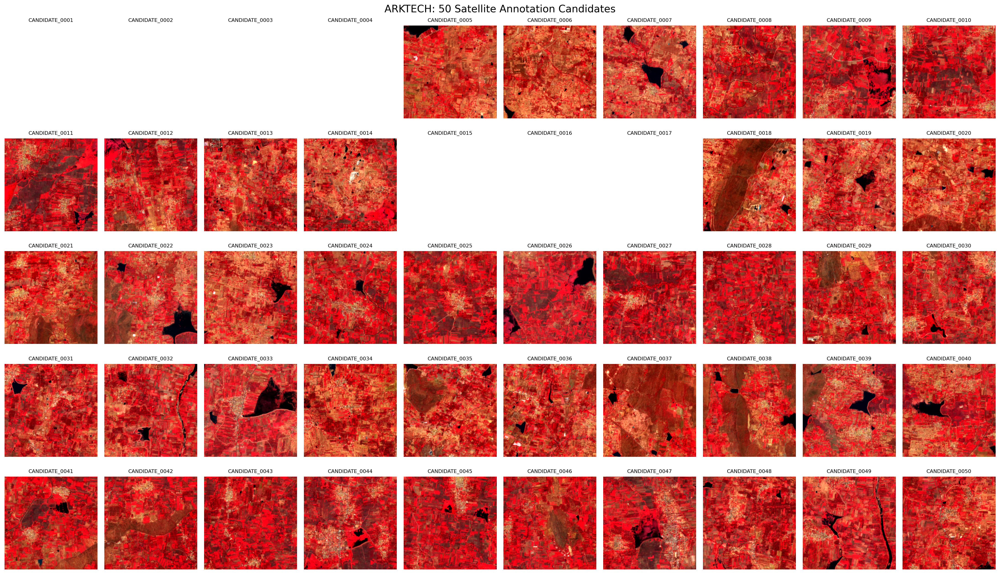

In [ ]:
from IPython.display import display, Image

PREVIEW = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Annotation_Candidates/Candidate_Preview.png"

display(Image(filename=PREVIEW))

In [ ]:
import os
import glob
import rasterio
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"
CANDIDATE_DIR = os.path.join(BASE, "Annotation_Candidates")

files = sorted(
    glob.glob(os.path.join(CANDIDATE_DIR, "CANDIDATE_*.tif"))
)

results = []

for path in files:
    with rasterio.open(path) as src:
        data = src.read()
        valid = np.isfinite(data)

        if src.nodata is not None:
            valid &= data != src.nodata

        valid_percentage = 100 * np.mean(valid)
        nonzero_percentage = 100 * np.mean(data != 0)

        results.append({
            "Tile": os.path.basename(path),
            "Valid_Pixels_Percent": round(valid_percentage, 2),
            "Nonzero_Percent": round(nonzero_percentage, 2),
            "Shape": str(data.shape),
            "Min": float(np.nanmin(data)),
            "Max": float(np.nanmax(data))
        })

df = pd.DataFrame(results)

display(df)

df.to_csv(
    os.path.join(CANDIDATE_DIR, "Candidate_Quality_Report.csv"),
    index=False
)

print("Quality report saved successfully!")

,Tile,Valid_Pixels_Percent,Nonzero_Percent,Shape,Min,Max
0,CANDIDATE_0001.tif,99.61,100.0,"(13, 256, 256)",-33.881260,5.732321e+05
1,CANDIDATE_0002.tif,99.61,100.0,"(13, 256, 256)",-34.888702,5.606562e+05
2,CANDIDATE_0003.tif,99.61,100.0,"(13, 256, 256)",-32.315441,5.489122e+05
3,CANDIDATE_0004.tif,99.91,100.0,"(13, 256, 256)",-35.219658,5.997535e+05
4,CANDIDATE_0005.tif,100.00,100.0,"(13, 256, 256)",-38.268650,4.685602e+05
5,CANDIDATE_0006.tif,100.00,100.0,"(13, 256, 256)",-36.451565,6.159372e+05
6,CANDIDATE_0007.tif,100.00,100.0,"(13, 256, 256)",-39.162842,6.503817e+05
7,CANDIDATE_0008.tif,100.00,100.0,"(13, 256, 256)",-25.834200,5.175420e+05
8,CANDIDATE_0009.tif,100.00,100.0,"(13, 256, 256)",-38.794796,7.327738e+05
9,CANDIDATE_0010.tif,100.00,100.0,"(13, 256, 256)",-25.980480,5.193976e+05


Quality report saved successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

path = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

print("Folder exists:", os.path.exists(path))

if os.path.exists(path):
    print("\nAvailable files:")
    for root, dirs, files in os.walk(path):
        for file in files:
            if file.endswith(('.keras', '.pkl', '.tif', '.csv')):
                print(os.path.join(root, file))

Folder exists: True

Available files:
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Crop_Training_Data (1).csv
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Crop_Training_Data.csv
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Satellite_Data_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Crop_Model.keras
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Scaler.pkl
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Stress_Mask_Mandya.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_0.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_256.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_512.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_768.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1024.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1280.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Field_Tiles/tile_0_1536.tif
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING

In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

extensions = ('.keras', '.h5', '.pt', '.pth', '.pkl', '.onnx')

print("========== ARKTECH TRAINED MODELS ==========")

for root, dirs, files in os.walk(BASE_PATH):
    for file in files:
        if file.endswith(extensions):
            print(os.path.join(root, file))

========== ARKTECH TRAINED MODELS ==========
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Crop_Model.keras
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Scaler.pkl


In [ ]:
import os

folders = [
    "Annotation_Candidates",
    "Field_Annotations",
    "Satellite_Data",
    "Models",
    "Training_Data"
]

for folder in folders:
    path = os.path.join(BASE_PATH, folder)

    print("\n", folder)

    if os.path.exists(path):
        print(os.listdir(path)[:15])
    else:
        print("Folder not found")


 Annotation_Candidates
['CANDIDATE_0001.tif', 'CANDIDATE_0002.tif', 'CANDIDATE_0003.tif', 'CANDIDATE_0004.tif', 'CANDIDATE_0005.tif', 'CANDIDATE_0006.tif', 'CANDIDATE_0007.tif', 'CANDIDATE_0008.tif', 'CANDIDATE_0009.tif', 'CANDIDATE_0010.tif', 'CANDIDATE_0011.tif', 'CANDIDATE_0012.tif', 'CANDIDATE_0013.tif', 'CANDIDATE_0014.tif', 'CANDIDATE_0015.tif']

 Field_Annotations
['GeoJSON', 'Masks', 'Preview']

 Satellite_Data
['tile_1024_3584.tif']

 Models
Folder not found

 Training_Data
Folder not found


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

print("========== MODEL SEARCH ==========")

for root, dirs, files in os.walk(BASE_PATH):
    for file in files:
        if file.lower().endswith((
            '.keras',
            '.h5',
            '.pkl',
            '.joblib',
            '.pt',
            '.pth',
            '.onnx'
        )):
            full_path = os.path.join(root, file)
            size = os.path.getsize(full_path) / (1024 * 1024)

            print(f"{file} | {size:.2f} MB")
            print(full_path)

========== MODEL SEARCH ==========
ARKTECH_Crop_Model.keras | 0.07 MB
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Crop_Model.keras
ARKTECH_Scaler.pkl | 0.00 MB
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/ARKTECH_Scaler.pkl


In [ ]:
import os

folders = {
    "GeoJSON": BASE_PATH + "/Field_Annotations/GeoJSON",
    "Masks": BASE_PATH + "/Field_Annotations/Masks",
    "Preview": BASE_PATH + "/Field_Annotations/Preview"
}

for name, path in folders.items():
    if os.path.exists(path):
        files = os.listdir(path)
        print(f"{name}: {len(files)} files")
        print(files[:10])

GeoJSON: 1 files
['tile_30.geojson']
Masks: 1 files
['tile_30_mask.png']
Preview: 0 files
[]


In [ ]:
import pandas as pd
import os

csv_path = BASE_PATH + "/Annotation_Candidates/Candidate_Index.csv"

if os.path.exists(csv_path):
    candidates = pd.read_csv(csv_path)

    print("Candidate dataset shape:", candidates.shape)
    display(candidates.head())

    print("\nColumns:")
    print(candidates.columns.tolist())

Candidate dataset shape: (50, 4)


,tile_id,image,row,col
0,CANDIDATE_0001,/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/A...,0,0
1,CANDIDATE_0002,/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/A...,0,256
2,CANDIDATE_0003,/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/A...,0,512
3,CANDIDATE_0004,/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/A...,0,768
4,CANDIDATE_0005,/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/A...,0,1024



Columns:
['tile_id', 'image', 'row', 'col']


In [ ]:
import rasterio

satellite_path = (
    BASE_PATH + "/Satellite_Data/tile_1024_3584.tif"
)

with rasterio.open(satellite_path) as src:
    print("Satellite image dimensions:", src.width, src.height)
    print("Number of bands:", src.count)
    print("CRS:", src.crs)
    print("Data type:", src.dtypes)
    print("Bounds:", src.bounds)

Satellite image dimensions: 256 256
Number of bands: 13
CRS: EPSG:4326
Data type: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
Bounds: BoundingBox(left=77.02191178652143, bottom=12.585127635929261, right=77.04490865779489, top=12.60812450720272)


In [ ]:
import tensorflow as tf
import joblib
import os

BASE_PATH = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

MODEL_PATH = os.path.join(
    BASE_PATH, "ARKTECH_Crop_Model.keras"
)

SCALER_PATH = os.path.join(
    BASE_PATH, "ARKTECH_Scaler.pkl"
)

model = tf.keras.models.load_model(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

print("MODEL LOADED SUCCESSFULLY")

print("\nINPUT SHAPE:")
print(model.input_shape)

print("\nOUTPUT SHAPE:")
print(model.output_shape)

print("\nSCALER FEATURES:")
print(scaler.n_features_in_)

print("\nMODEL SUMMARY:")
model.summary()

MODEL LOADED SUCCESSFULLY

INPUT SHAPE:
(None, 13)

OUTPUT SHAPE:
(None, 3)

SCALER FEATURES:
13

MODEL SUMMARY:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,667 (41.67 KB)

 Trainable params: 3,555 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,112 (27.79 KB)

In [ ]:
import os

print("SEARCHING FOR TRAINING DATASETS")

for root, dirs, files in os.walk(BASE_PATH):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

SEARCHING FOR TRAINING DATASETS
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Crop_Training_Data (1).csv
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Crop_Training_Data.csv
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Multi_Tile_Dataset/ARKTECH_Dataset_Index.csv
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Annotation_Candidates/Candidate_Index.csv
/content/drive/MyDrive/ARKTECH_DEEP_LEARNING/Annotation_Candidates/Candidate_Quality_Report.csv


In [ ]:
import pandas as pd

CSV_PATH = BASE_PATH + "/Crop_Training_Data.csv"

df = pd.read_csv(CSV_PATH)

print("DATASET SHAPE:", df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATASET PREVIEW:")
display(df.head())

print("\nDATA TYPES:")
print(df.dtypes)

DATASET SHAPE: (30, 17)

COLUMN NAMES:
['system:index', 'B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'Contrast', 'Entropy', 'NDVI', 'NDWI', 'SMI', 'VH', 'VV', 'crop', 'label', '.geo']

DATASET PREVIEW:


,system:index,B11,B12,B2,B3,B4,B8,Contrast,Entropy,NDVI,NDWI,SMI,VH,VV,crop,label,.geo
0,0_0,2028.0,1648.0,833.0,1028.0,1152.0,2115.0,33263.350,4.353742,0.294766,-0.345848,0.879180,-15.323600,-7.416408,Sugarcane,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1_0,1515.5,791.0,352.5,533.5,369.5,2329.0,105344.260,4.272599,0.726144,-0.627249,0.897114,-14.068967,-7.057728,Sugarcane,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2_0,2359.0,1954.0,640.0,810.0,982.0,1458.0,8513.697,4.353742,0.195082,-0.285714,0.695485,-19.941912,-11.090300,Sugarcane,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,3_0,3130.0,2277.0,808.0,1098.0,1332.0,2592.0,76549.984,4.353742,0.321101,-0.404878,0.826764,-15.992419,-8.464725,Sugarcane,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,4_0,1589.0,766.0,432.0,672.0,450.0,3189.0,134556.170,4.348928,0.752679,-0.651904,0.770623,-16.426996,-9.587546,Sugarcane,0,"{""type"":""MultiPoint"",""coordinates"":[]}"



DATA TYPES:
system:index     object
B11             float64
B12             float64
B2              float64
B3              float64
B4              float64
B8              float64
Contrast        float64
Entropy         float64
NDVI            float64
NDWI            float64
SMI             float64
VH              float64
VV              float64
crop             object
label             int64
.geo             object
dtype: object


In [ ]:
import tensorflow as tf
import joblib
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

# Load model
model = tf.keras.models.load_model(
    BASE_PATH + "/ARKTECH_Crop_Model.keras"
)

# Load scaler
scaler = joblib.load(
    BASE_PATH + "/ARKTECH_Scaler.pkl"
)

# Load dataset
df = pd.read_csv(
    BASE_PATH + "/Crop_Training_Data.csv"
)

print("=" * 45)
print("ARKTECH MODEL VERIFICATION")
print("=" * 45)

print("Model input:", model.input_shape)
print("Model output:", model.output_shape)
print("Scaler features:", scaler.n_features_in_)

print("\nAvailable dataset columns:")
print(df.columns.tolist())

print("\nCrop distribution:")
print(df["crop"].value_counts())

print("\nNumerical label mapping:")

print(
    df[["crop", "label"]]
    .drop_duplicates()
    .sort_values("label")
)

print("\nMODEL VERIFICATION COMPLETED")

ARKTECH MODEL VERIFICATION
Model input: (None, 13)
Model output: (None, 3)
Scaler features: 13

Available dataset columns:
['system:index', 'B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'Contrast', 'Entropy', 'NDVI', 'NDWI', 'SMI', 'VH', 'VV', 'crop', 'label', '.geo']

Crop distribution:
crop
Sugarcane    10
Rice         10
Fallow       10
Name: count, dtype: int64

Numerical label mapping:
         crop  label
0   Sugarcane      0
10       Rice      1
20     Fallow      2

MODEL VERIFICATION COMPLETED


In [ ]:
FEATURES = [
    "B11", "B12", "B2", "B3", "B4", "B8",
    "Contrast", "Entropy", "NDVI", "NDWI",
    "SMI", "VH", "VV"
]

print("Expected features:", len(FEATURES))
print("Scaler features:", scaler.n_features_in_)

print("Model input:", model.input_shape)

assert len(FEATURES) == scaler.n_features_in_, \
    "Feature count mismatch!"

assert len(FEATURES) == model.input_shape[-1], \
    "Model input mismatch!"

print("FEATURE VERIFICATION SUCCESSFUL")

Expected features: 13
Scaler features: 13
Model input: (None, 13)
FEATURE VERIFICATION SUCCESSFUL


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
import os

BASE_PATH = "/content/drive/MyDrive/ARKTECH_DEEP_LEARNING"

model = tf.keras.models.load_model(
    BASE_PATH + "/ARKTECH_Crop_Model.keras"
)

scaler = joblib.load(
    BASE_PATH + "/ARKTECH_Scaler.pkl"
)

FEATURES = [
    "B11", "B12", "B2", "B3", "B4", "B8",
    "Contrast", "Entropy", "NDVI", "NDWI",
    "SMI", "VH", "VV"
]

CLASS_NAMES = {
    0: "Sugarcane",
    1: "Rice",
    2: "Fallow"
}

def predict_crop(input_data):

    data = pd.DataFrame(
        [input_data],
        columns=FEATURES
    )

    scaled_data = scaler.transform(data)

    probabilities = model.predict(
        scaled_data,
        verbose=0
    )[0]

    predicted_class = int(np.argmax(probabilities))

    return {
        "predicted_crop": CLASS_NAMES[predicted_class],
        "class_id": predicted_class,
        "confidence": float(probabilities[predicted_class]),
        "probabilities": {
            CLASS_NAMES[i]: float(probabilities[i])
            for i in range(3)
        }
    }

print("ARKTECH PREDICTION FUNCTION CREATED")

ARKTECH PREDICTION FUNCTION CREATED


In [ ]:
df = pd.read_csv(
    BASE_PATH + "/Crop_Training_Data.csv"
)

sample = df[FEATURES].iloc[0].tolist()

result = predict_crop(sample)

print("========== ARKTECH PREDICTION ==========")

print("Input features:", sample)

for key, value in result.items():
    print(key, ":", value)

========== ARKTECH PREDICTION ==========
Input features: [2028.0, 1648.0, 833.0, 1028.0, 1152.0, 2115.0, 33263.35, 4.3537416, 0.29476583, -0.3458479, 0.8791796, -15.3236, -7.416408]
predicted_crop : Sugarcane
class_id : 0
confidence : 1.0
probabilities : {'Sugarcane': 1.0, 'Rice': 0.0, 'Fallow': 0.0}


In [ ]:
correct = 0

for _, row in df.iterrows():

    sample = row[FEATURES].tolist()

    result = predict_crop(sample)

    actual = row["crop"]
    predicted = result["predicted_crop"]

    if actual == predicted:
        correct += 1

    print(
        "Actual:", actual,
        "| Predicted:", predicted
    )

print("\nTraining sample accuracy:",
      correct / len(df) * 100, "%")

Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Sugarcane | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Rice | Predicted: Sugarcane
Actual: Fallow | Predicted: Sugarcane
Actual: Fallow | Predicted: Sugarcane
Actual: Fallow | Predicted: Sugarcane
Actual: Fallow | Predicted: Sugarcane
Actual: Fallow | Predicted: Sugarcane
Actual: Fallow | Predicted: Sugarcane
Ac

In [ ]:
import os
import json
import shutil

DEPLOY = "/content/ARKTECH_DEPLOYMENT"

os.makedirs(DEPLOY, exist_ok=True)

shutil.copy(
    BASE_PATH + "/ARKTECH_Crop_Model.keras",
    DEPLOY
)

shutil.copy(
    BASE_PATH + "/ARKTECH_Scaler.pkl",
    DEPLOY
)

metadata = {
    "project": "ARKTECH",
    "model": "Crop Classification",
    "input_features": FEATURES,
    "classes": CLASS_NAMES
}

with open(DEPLOY + "/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("ARKTECH DEPLOYMENT FILES CREATED")
print(os.listdir(DEPLOY))

ARKTECH DEPLOYMENT FILES CREATED
['metadata.json', 'ARKTECH_Scaler.pkl', 'ARKTECH_Crop_Model.keras']


In [ ]:
DRIVE_DEPLOY = BASE_PATH + "/Deployment"

os.makedirs(DRIVE_DEPLOY, exist_ok=True)

for file in os.listdir(DEPLOY):
    shutil.copy2(
        os.path.join(DEPLOY, file),
        os.path.join(DRIVE_DEPLOY, file)
    )

print("DEPLOYMENT SAVED TO GOOGLE DRIVE")

DEPLOYMENT SAVED TO GOOGLE DRIVE


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/ARKTECH_DEPLOYMENT",
    "zip",
    "/content/ARKTECH_DEPLOYMENT"
)

files.download("/content/ARKTECH_DEPLOYMENT.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!git config --global user.name "Dhruva Talibidi"
!git config --global user.email "dhruvatalibidi4121@gmail.com"